# Running profiles: clustering athletes

**Goal:** group the athletes in the Endomondo dataset into *running profiles* using unsupervised learning, and show how well each athlete fits their profile.

| Step | What happens |
|---|---|
| 1 | Load the workouts |
| 2 | Per workout: derive features from the HR / speed time series |
| 3 | Per athlete: combine workouts into one feature row |
| 4 | Pick features (remove redundant ones) |
| 5 | Scale the features |
| 6 | Choose the number of clusters *k* |
| 7 | **k-means** on athletes with enough data → profiles |
| 8 | `km.predict`: assign the low-data athletes to the nearest profile |
| 9 | **Gaussian mixture**: a probability per profile for *every* athlete |
| 10 | Profile cards for example athletes |
| 11 | Validation: same profile in a different period? (split over time) |
| 12 | Robustness: does hierarchical clustering find the same profiles? |
| 13 | Final labels with confidence |

Run from the repo's `.venv`. Needs `data/endomondo-hr-prediction-v2/dataset.parquet` (`python scripts/download_data.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             silhouette_samples, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
SRC = ROOT / "data" / "endomondo-hr-prediction-v2" / "dataset.parquet"
OUT = ROOT / "analysis" / "athlete_profiles" / "output"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
MIN_WORKOUTS = 10

# --- chart style ---------------------------------------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"
BLUE, ORANGE, AQUA, RED, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, NEUTRAL, RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 2,
})

## Step 1 · Load the workouts

Each row is one workout with 500 timesteps of heart rate, speed and altitude. We only read the columns we need.

In [2]:
cols = ["workout_id", "user_id", "workout_type", "duration_min", "timestamp", "heart_rate",
        "speed", "hr_mean", "hr_max", "speed_mean", "altitude_gain"]
df = pd.read_parquet(SRC, columns=cols)
print(f"{len(df):,} workouts from {df.user_id.nunique()} athletes")
df.drop(columns=["timestamp", "heart_rate", "speed"]).head()

40,186 workouts from 761 athletes


,workout_id,user_id,workout_type,duration_min,hr_mean,hr_max,speed_mean,altitude_gain
0,296982347,4969375,RECOVERY,108.383333,134.945238,162.285714,12.098456,74.669049
1,294163731,4969375,STEADY,50.583333,150.364071,184.571429,11.376965,108.942858
2,293171954,4969375,RECOVERY,76.516667,135.692914,154.428571,12.756218,161.614287
3,286519750,4969375,RECOVERY,101.316667,130.977900,172.142857,11.863505,108.514287
4,282210994,4969375,RECOVERY,70.083333,142.158700,159.857143,13.452795,149.328571


## Step 2 · Features per workout

The summary columns (mean HR, mean speed) say *how hard and how fast*. The time series also tells us *how* someone runs. We add four measures, two of which come from the persona measure designs (`docs/endomondo-hr-persona-measure-designs.xlsx`):

| Feature | Formula | Meaning |
|---|---|---|
| `efficiency` | 100 · speed / HR | km/h per 100 heartbeats: aerobic fitness |
| `speed_cv` | std(speed) / mean(speed) | steady run (low) vs intervals / stop-and-go (high) |
| `opening_pace_ratio` (M-01) | mean speed first 15% / rest | > 1 = starts too fast |
| `cardiac_drift_pct` (M-04) | efficiency drop 1st → 2nd half, in % | high = tires / overheats during the run |

In [3]:
hr = np.stack(df["heart_rate"].to_numpy()).astype("float32")   # shape (workouts, 500)
sp = np.stack(df["speed"].to_numpy()).astype("float32")
n_pts = sp.shape[1]
cut15, half = int(n_pts * 0.15), n_pts // 2

ef = sp / np.clip(hr, 1, None)                                  # efficiency per timestep
ef1, ef2 = ef[:, :half].mean(1), ef[:, half:].mean(1)

w = pd.DataFrame({
    "workout_id": df["workout_id"].to_numpy(),
    "user_id": df["user_id"].to_numpy(),
    "workout_type": df["workout_type"].to_numpy(),
    "date": pd.to_datetime(df["timestamp"].map(lambda t: t[0]).to_numpy(), unit="s"),
    "distance_km": (df["speed_mean"] * df["duration_min"] / 60).to_numpy(),
    "speed_kmh": df["speed_mean"].to_numpy(),
    "hr_mean": df["hr_mean"].to_numpy(),
    "hr_max": df["hr_max"].to_numpy(),
    "altitude_gain": df["altitude_gain"].to_numpy(),
    "efficiency": 100 * df["speed_mean"].to_numpy() / df["hr_mean"].to_numpy(),
    "speed_cv": sp.std(1) / np.clip(sp.mean(1), 0.1, None),
    "opening_pace_ratio": sp[:, :cut15].mean(1) / np.clip(sp[:, cut15:].mean(1), 0.1, None),
    "cardiac_drift_pct": 100 * (ef1 - ef2) / np.clip(ef1, 1e-6, None),
})
w.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
workout_id,40186.0,381311625.6505,1704139.0,279772077.75,377129735.0,490529233.25,662935377.0,150786415.499425
user_id,40186.0,4617016.606978,69.0,1417260.0,3432842.0,7285980.0,15481421.0,3913413.563261
date,40186,2014-06-13 20:54:20.616085,2007-02-07 00:32:39,2013-11-17 19:56:08,2014-07-02 14:20:41.500000,2015-03-10 02:34:08,2016-01-01 13:00:09,NaN
distance_km,40186.0,12.344162,0.751798,8.487572,10.871492,14.860614,56.197463,6.190185
speed_kmh,40186.0,11.00378,2.097653,9.801772,11.016195,12.195778,23.369736,1.861634
hr_mean,40186.0,149.404458,120.00959,141.240187,149.552633,157.428579,191.214052,12.003108
hr_max,40186.0,166.643416,126.142857,158.285714,167.142857,175.5,200.0,12.788832
altitude_gain,40186.0,110.272719,0.0,45.779166,81.064286,135.40003,3200.47147,114.82544
efficiency,40186.0,7.38171,1.391808,6.63161,7.383946,8.157312,18.222119,1.20799
speed_cv,40186.0,0.119411,0.014195,0.065248,0.09333,0.143434,2.213164,0.086845


### What do these features look like in a real run?

One workout with a fast start and clear cardiac drift: the shaded area is the first 15% of the run, and the dashed lines are the averages each feature compares.

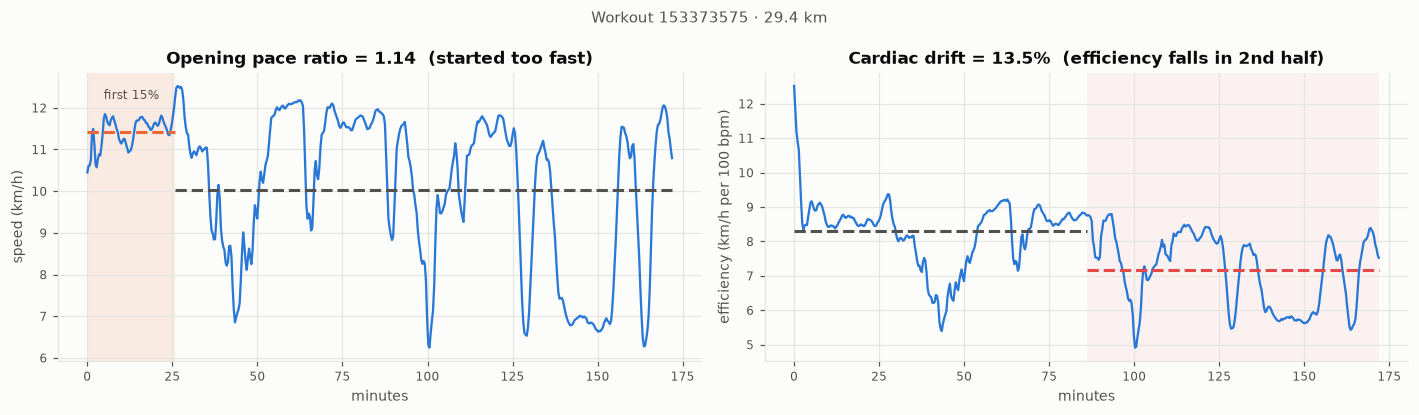

In [4]:
cand = w[(w.opening_pace_ratio.between(1.12, 1.25)) & (w.cardiac_drift_pct.between(10, 15))]
i = cand.index[0]
t = np.arange(n_pts) / n_pts * df.loc[i, "duration_min"]
t15, thalf = t[cut15], t[half]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
a1.axvspan(0, t15, color=ORANGE, alpha=0.12, lw=0)
a1.plot(t, sp[i], color=BLUE, lw=1.5)
a1.hlines(sp[i, :cut15].mean(), 0, t15, color=ORANGE, ls="--")
a1.hlines(sp[i, cut15:].mean(), t15, t[-1], color=INK2, ls="--")
a1.set(title=f"Opening pace ratio = {w.loc[i, 'opening_pace_ratio']:.2f}  (started too fast)",
       xlabel="minutes", ylabel="speed (km/h)")
a1.text(t15 / 2, a1.get_ylim()[1] * 0.97, "first 15%", ha="center", va="top", fontsize=8, color=INK2)

a2.axvspan(thalf, t[-1], color=RED, alpha=0.06, lw=0)
a2.plot(t, 100 * ef[i], color=BLUE, lw=1.5)
a2.hlines(100 * ef1[i], 0, thalf, color=INK2, ls="--")
a2.hlines(100 * ef2[i], thalf, t[-1], color=RED, ls="--")
a2.set(title=f"Cardiac drift = {w.loc[i, 'cardiac_drift_pct']:.1f}%  (efficiency falls in 2nd half)",
       xlabel="minutes", ylabel="efficiency (km/h per 100 bpm)")
fig.suptitle(f"Workout {w.loc[i, 'workout_id']} · {w.loc[i, 'distance_km']:.1f} km", fontsize=10, color=INK2)
fig.tight_layout()

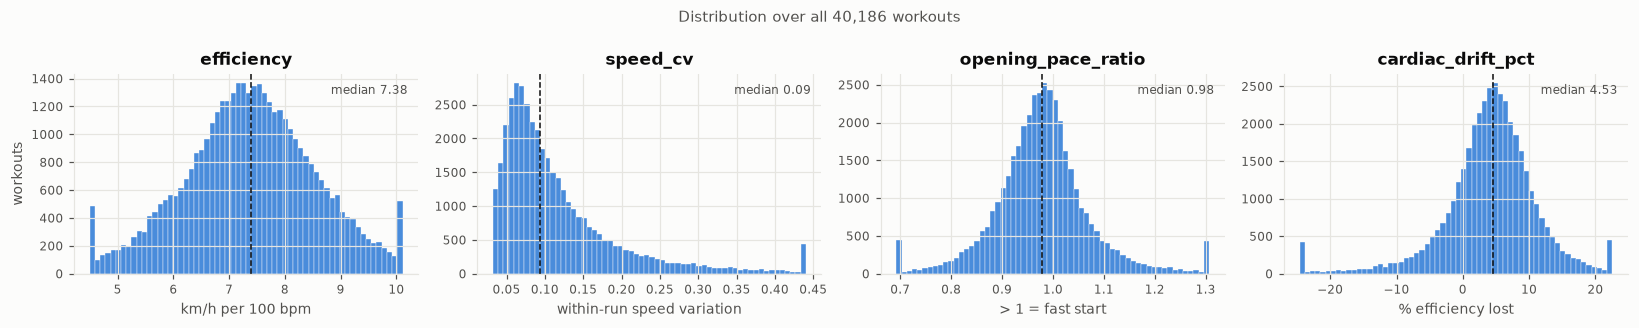

In [5]:
feat_info = {
    "efficiency": "km/h per 100 bpm", "speed_cv": "within-run speed variation",
    "opening_pace_ratio": "> 1 = fast start", "cardiac_drift_pct": "% efficiency lost",
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (f, label) in zip(axes, feat_info.items()):
    lo, hi = w[f].quantile([0.01, 0.99])
    ax.hist(w[f].clip(lo, hi), bins=60, color=BLUE, alpha=0.85, edgecolor="#fcfcfb", lw=0.3)
    ax.axvline(w[f].median(), color=INK, ls="--", lw=1)
    ax.set(title=f, xlabel=label)
    ax.text(0.97, 0.95, f"median {w[f].median():.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=INK2)
axes[0].set_ylabel("workouts")
fig.suptitle("Distribution over all 40,186 workouts", fontsize=10, color=INK2)
fig.tight_layout()

## Step 3 · One row per athlete

We cluster **athletes**, not workouts, so each athlete's workouts are combined into one feature row. We use **medians**, so one broken GPS track doesn't skew an athlete.

In [6]:
def athlete_table(wk: pd.DataFrame) -> pd.DataFrame:
    # Combine a set of workouts into one feature row per athlete (reused in step 11).
    g = wk.groupby("user_id")
    span_weeks = (g["date"].max() - g["date"].min()).dt.days / 7
    return pd.DataFrame({
        "workouts": g.size(),
        "runs_per_week": g.size() / span_weeks.clip(lower=1),
        "distance_km": g["distance_km"].median(),
        "long_run_km": g["distance_km"].quantile(0.9),
        "speed_kmh": g["speed_kmh"].median(),
        "efficiency": g["efficiency"].median(),
        "rel_intensity": g["hr_mean"].median() / g["hr_max"].quantile(0.95),
        "share_intensive": g["workout_type"].apply(lambda s: (s == "INTENSIVE").mean()),
        "speed_cv": g["speed_cv"].median(),
        "opening_pace_ratio": g["opening_pace_ratio"].median(),
        "cardiac_drift_pct": g["cardiac_drift_pct"].median(),
        "climb_m_per_km": g["altitude_gain"].sum() / g["distance_km"].sum(),
    })

athletes = athlete_table(w)
print(f"{len(athletes)} athletes, missing values: {int(athletes.isna().sum().sum())}")
athletes.describe().T.round(2)

761 athletes, missing values: 0


,count,mean,std,min,25%,50%,75%,max
workouts,761.0,52.81,67.01,1.00,9.00,28.00,71.00,673.00
runs_per_week,761.0,0.67,0.61,0.02,0.23,0.52,1.00,6.42
distance_km,761.0,10.86,3.73,2.08,8.83,10.47,12.46,43.28
long_run_km,761.0,16.90,6.64,2.08,12.29,16.26,20.84,47.98
speed_kmh,761.0,10.66,1.75,5.39,9.54,10.67,11.83,19.69
efficiency,761.0,7.12,1.21,4.09,6.29,7.13,7.87,15.21
rel_intensity,761.0,0.83,0.04,0.69,0.80,0.83,0.86,0.97
share_intensive,761.0,0.07,0.16,0.00,0.00,0.00,0.06,1.00
speed_cv,761.0,0.12,0.07,0.03,0.08,0.10,0.14,0.87
opening_pace_ratio,761.0,0.99,0.08,0.00,0.96,0.99,1.01,1.41


### How many workouts does each athlete have?

An athlete with 1–2 runs has very noisy features (runs per week can't really be measured, and the INTENSIVE share is either 0% or 100%). So we **learn** the profiles only from athletes with at least 10 workouts and **assign** the others later (step 8–9).

core: 569 athletes (39,459 workouts) · low-data: 192 athletes (727 workouts)


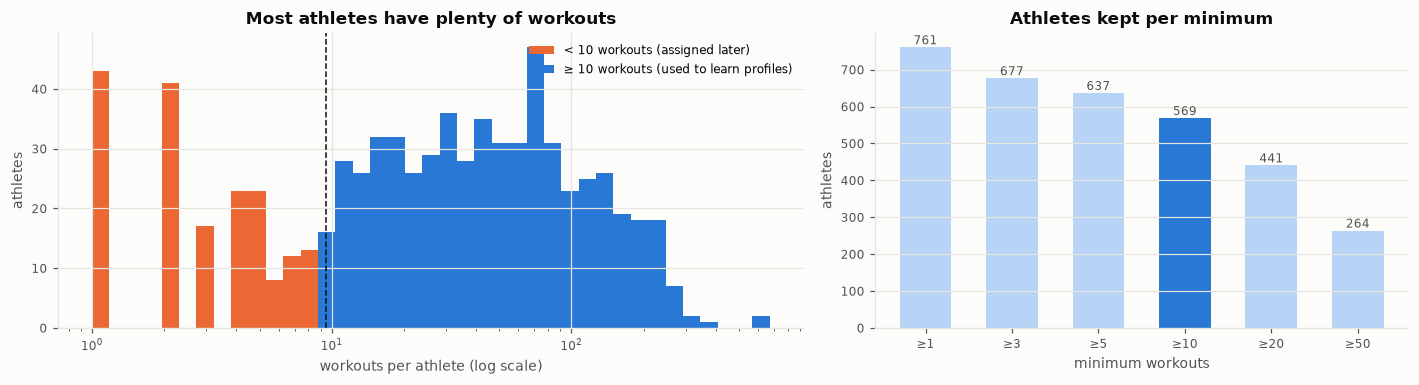

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
bins = np.logspace(0, np.log10(athletes.workouts.max()), 40)
n = athletes.workouts
a1.hist(n[n < MIN_WORKOUTS], bins=bins, color=ORANGE, label=f"< {MIN_WORKOUTS} workouts (assigned later)")
a1.hist(n[n >= MIN_WORKOUTS], bins=bins, color=BLUE, label=f"≥ {MIN_WORKOUTS} workouts (used to learn profiles)")
a1.axvline(MIN_WORKOUTS - 0.5, color=INK, ls="--", lw=1)
a1.set(xscale="log", xlabel="workouts per athlete (log scale)", ylabel="athletes",
       title="Most athletes have plenty of workouts")
a1.legend()

thr = [1, 3, 5, 10, 20, 50]
kept = [(n >= t).sum() for t in thr]
bars = a2.bar([f"≥{t}" for t in thr], kept, color=[BLUE if t == MIN_WORKOUTS else "#b7d3f6" for t in thr], width=0.6)
a2.bar_label(bars, fontsize=8, color=INK2)
a2.set(title="Athletes kept per minimum", xlabel="minimum workouts", ylabel="athletes")
a2.grid(axis="x", visible=False)
fig.tight_layout()

core = athletes[athletes.workouts >= MIN_WORKOUTS].copy()
low = athletes[athletes.workouts < MIN_WORKOUTS].copy()
print(f"core: {len(core)} athletes ({core.workouts.sum():,} workouts) · "
      f"low-data: {len(low)} athletes ({low.workouts.sum():,} workouts)")

## Step 4 · Choose the features

k-means measures distance across *all* features at once. Two features that say the same thing therefore count **double**. Spearman correlation shows which ones overlap.

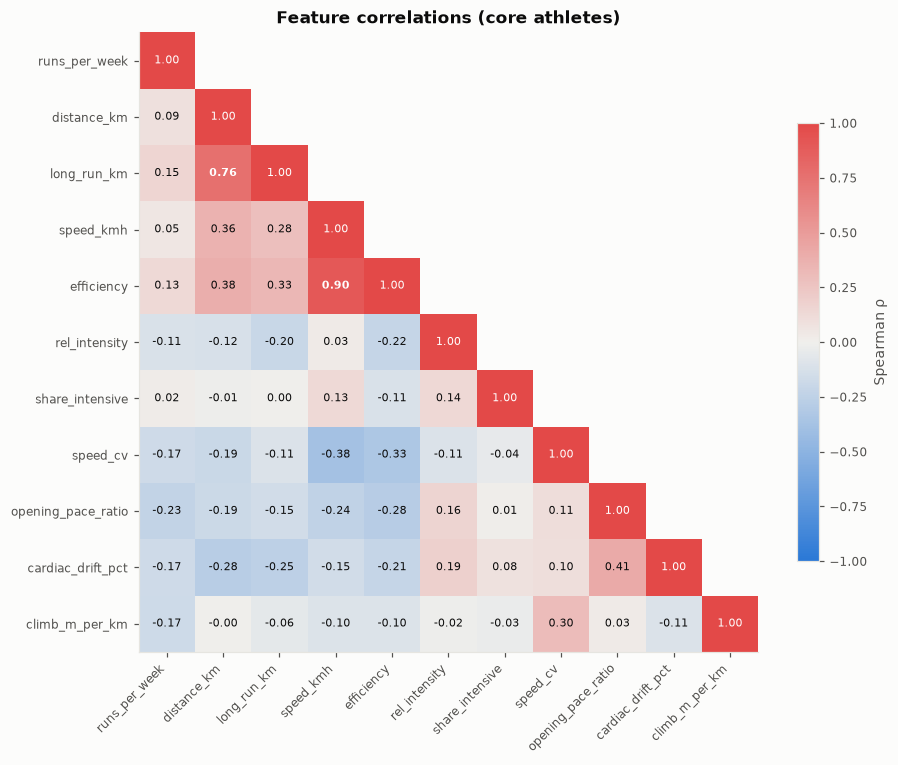

In [8]:
CANDIDATES = [c for c in athletes.columns if c != "workouts"]
corr = core[CANDIDATES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.where(mask, np.nan, corr), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for r in range(len(corr)):
    for c in range(r + 1):
        v = corr.iat[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else INK, fontweight="bold" if abs(v) > 0.7 and r != c else None)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Feature correlations (core athletes)")
fig.tight_layout()

Two pairs are strongly correlated:

* `speed_kmh` ↔ `efficiency` (ρ ≈ 0.9): faster runners are mostly the efficient runners. We keep **efficiency** because it corrects for effort.
* `distance_km` ↔ `long_run_km` (ρ ≈ 0.76): we keep the median **distance**.

That leaves 9 clustering features. Below are their distributions *before* scaling: very different units, and a few are strongly skewed.

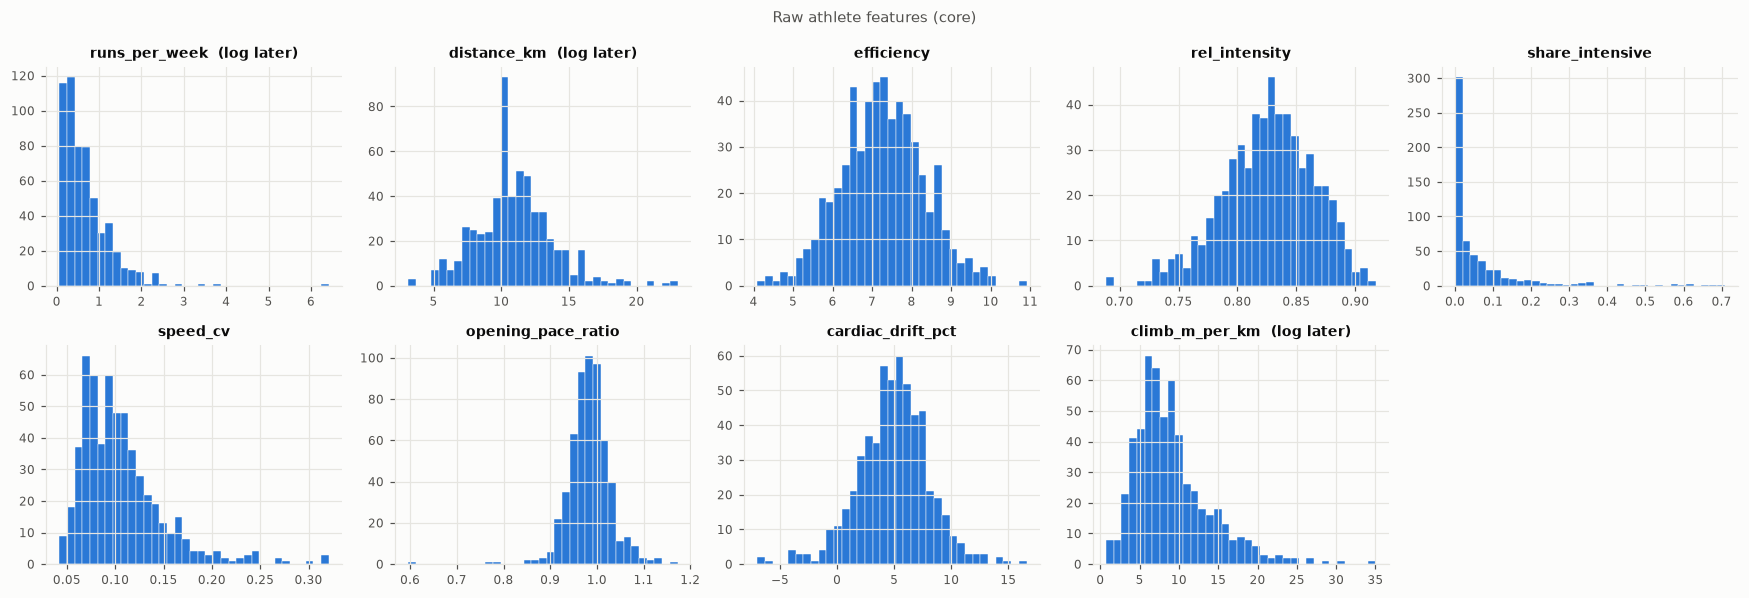

In [9]:
FEATURES = ["runs_per_week", "distance_km", "efficiency", "rel_intensity", "share_intensive",
            "speed_cv", "opening_pace_ratio", "cardiac_drift_pct", "climb_m_per_km"]
LOG_FEATURES = ["runs_per_week", "distance_km", "climb_m_per_km"]

fig, axes = plt.subplots(2, 5, figsize=(16, 5.5))
for ax, f in zip(axes.flat, FEATURES):
    ax.hist(core[f], bins=35, color=BLUE, edgecolor="#fcfcfb", lw=0.3)
    ax.set_title(f + ("  (log later)" if f in LOG_FEATURES else ""), fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Raw athlete features (core)", fontsize=10, color=INK2)
fig.tight_layout()

## Step 5 · Scaling

1. **log** the skewed features, so a few extreme athletes don't dominate.
2. **Clip** to the 1st–99th percentile, which takes care of broken GPS data.
3. **Standardise** to z-scores (mean 0, std 1), so every feature weighs the same.

Important: all three steps are *learned* from the core athletes and then *applied unchanged* to the low-data athletes. That's the same rule as with a train/test split.

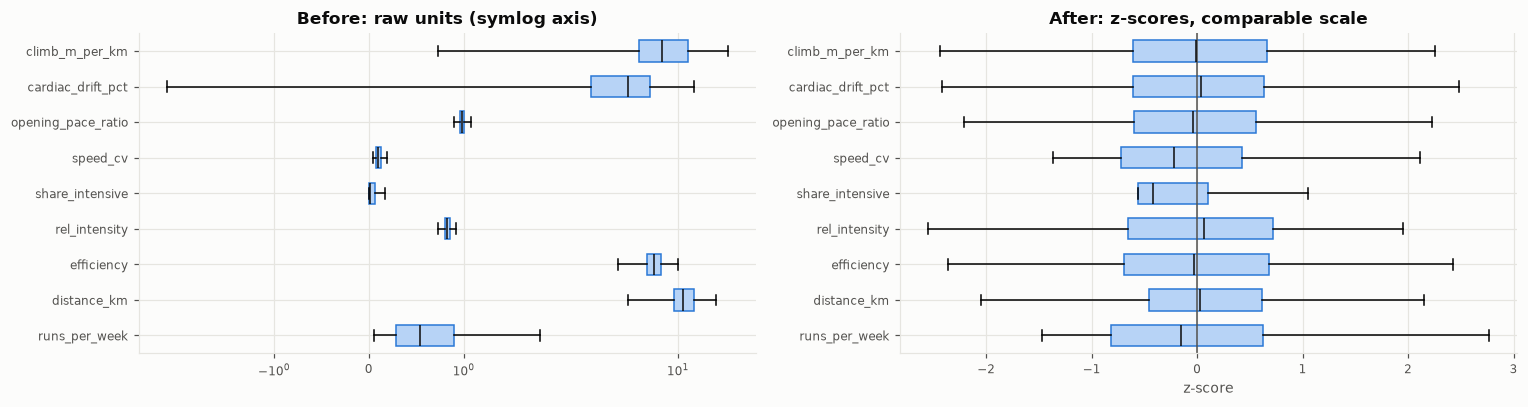

In [10]:
def prepare(a: pd.DataFrame) -> pd.DataFrame:
    X = a[FEATURES].copy()
    for c in LOG_FEATURES:
        X[c] = np.log1p(X[c])
    return X

X_core_raw = prepare(core)
lo, hi = X_core_raw.quantile(0.01), X_core_raw.quantile(0.99)
scaler = StandardScaler().fit(X_core_raw.clip(lo, hi, axis=1))

def transform(a: pd.DataFrame) -> np.ndarray:
    return scaler.transform(prepare(a).clip(lo, hi, axis=1))

X = transform(core)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 3.8), sharey=False)
bp_kw = dict(orientation="horizontal", patch_artist=True, widths=0.6, showfliers=False,
             medianprops=dict(color=INK), boxprops=dict(facecolor="#b7d3f6", edgecolor=BLUE))
a1.boxplot([core[f] for f in FEATURES], tick_labels=FEATURES, **bp_kw)
a1.set(xscale="symlog", title="Before: raw units (symlog axis)")
a2.boxplot(X.T.tolist(), tick_labels=FEATURES, **bp_kw)
a2.axvline(0, color=INK2, lw=1)
a2.set(title="After: z-scores, comparable scale", xlabel="z-score")
fig.tight_layout()

## Step 6 · How many clusters?

k-means needs *k* up front. We try k = 2…10 and look at four measures:

* **Inertia (elbow):** total distance to the centres. It always goes down, so look for the "elbow".
* **Silhouette:** how much better an athlete fits its own cluster than the nearest other one (−1…1, higher is better).
* **Davies-Bouldin:** how compact vs how separated the clusters are (lower is better).
* **Stability (ARI):** refit on 20 bootstrap samples. Do the same groups come back? (1 = always identical)

,inertia,silhouette,davies_bouldin,stability
k,,,,
2,4316.997,0.157,2.177,0.802
3,3937.926,0.158,1.941,0.554
4,3622.188,0.137,1.930,0.432
5,3364.138,0.124,1.897,0.525
6,3164.338,0.120,1.879,0.479
7,3001.633,0.113,1.860,0.505
8,2886.740,0.110,1.862,0.428
9,2790.025,0.107,1.852,0.427
10,2702.686,0.107,1.830,0.423


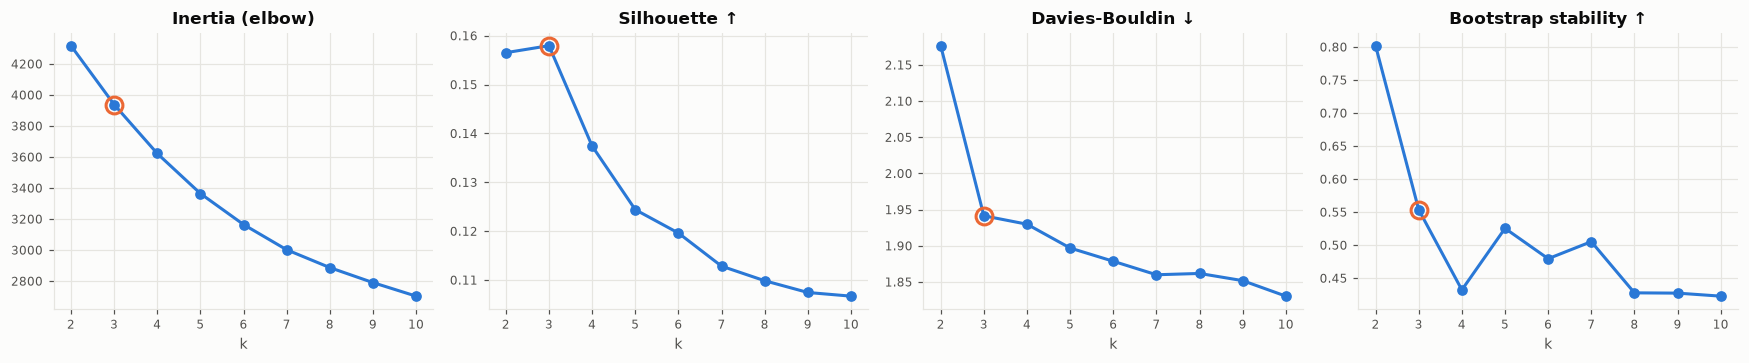

In [11]:
rng = np.random.default_rng(SEED)
rows = []
for k in range(2, 11):
    km_k = KMeans(k, n_init=20, random_state=SEED).fit(X)
    aris = []
    for _ in range(20):
        idx = rng.choice(len(X), len(X), replace=True)
        kb = KMeans(k, n_init=5, random_state=int(rng.integers(1e9))).fit(X[idx])
        aris.append(adjusted_rand_score(km_k.labels_, kb.predict(X)))
    rows.append(dict(k=k, inertia=km_k.inertia_, silhouette=silhouette_score(X, km_k.labels_),
                     davies_bouldin=davies_bouldin_score(X, km_k.labels_), stability=np.mean(aris)))
scores = pd.DataFrame(rows).set_index("k")

K = 3
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
titles = {"inertia": "Inertia (elbow)", "silhouette": "Silhouette ↑",
          "davies_bouldin": "Davies-Bouldin ↓", "stability": "Bootstrap stability ↑"}
for ax, (col, title) in zip(axes, titles.items()):
    ax.plot(scores.index, scores[col], color=BLUE, marker="o", ms=6)
    ax.plot(K, scores.loc[K, col], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
    ax.set(title=title, xlabel="k", xticks=scores.index)
fig.tight_layout()
scores.round(3)

**k = 3** is the best trade-off: the silhouette is almost the highest, and above k = 3 the stability drops clearly (the groups change between refits). k = 2 is more stable but too coarse to call "profiles".

Note that the silhouette is low overall (~0.15). Runners form a **sliding scale** rather than sharply separated groups. The silhouette plot below shows this per athlete: bars below 0 are athletes sitting closer to another cluster.

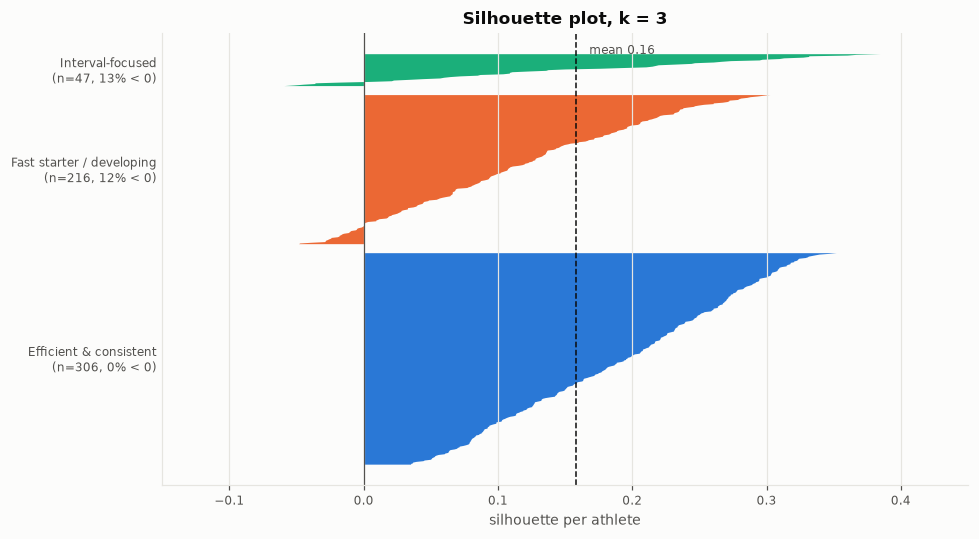

In [12]:
km = KMeans(K, n_init=50, random_state=SEED).fit(X)
zprof = pd.DataFrame(X, columns=FEATURES).groupby(km.labels_).mean()

# Give the clusters a fixed, meaningful name (independent of k-means' random numbering).
def name_clusters(z: pd.DataFrame) -> dict:
    c_int = z["share_intensive"].idxmax()
    c_eff = z.drop(c_int)["efficiency"].idxmax()
    c_dev = (set(z.index) - {c_int, c_eff}).pop()
    return {c_eff: "Efficient & consistent", c_dev: "Fast starter / developing", c_int: "Interval-focused"}

NAMES = name_clusters(zprof)
ORDER = ["Efficient & consistent", "Fast starter / developing", "Interval-focused"]
COLOR = dict(zip(ORDER, [BLUE, ORANGE, AQUA]))
core["profile"] = pd.Categorical([NAMES[l] for l in km.labels_], categories=ORDER)

sil = silhouette_samples(X, km.labels_)
fig, ax = plt.subplots(figsize=(9, 5))
y0, ticks = 0, []
for name in ORDER:
    s = np.sort(sil[core.profile == name])
    ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=COLOR[name], lw=0)
    ticks.append((y0 + len(s) / 2, f"{name}\n(n={len(s)}, {np.mean(s < 0):.0%} < 0)"))
    y0 += len(s) + 12
ax.axvline(sil.mean(), color=INK, ls="--", lw=1)
ax.text(sil.mean() + 0.01, y0, f"mean {sil.mean():.2f}", fontsize=8, color=INK2, va="top")
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks([t for t, _ in ticks], [l for _, l in ticks], fontsize=8)
ax.tick_params(axis="y", length=0)
ax.set(xlabel="silhouette per athlete", title=f"Silhouette plot, k = {K}", xlim=(-0.15, 0.45))
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Step 7 · The profiles

How does each profile differ from the average athlete? The heatmap shows the cluster centre in z-scores: **red = above average, blue = below average**.

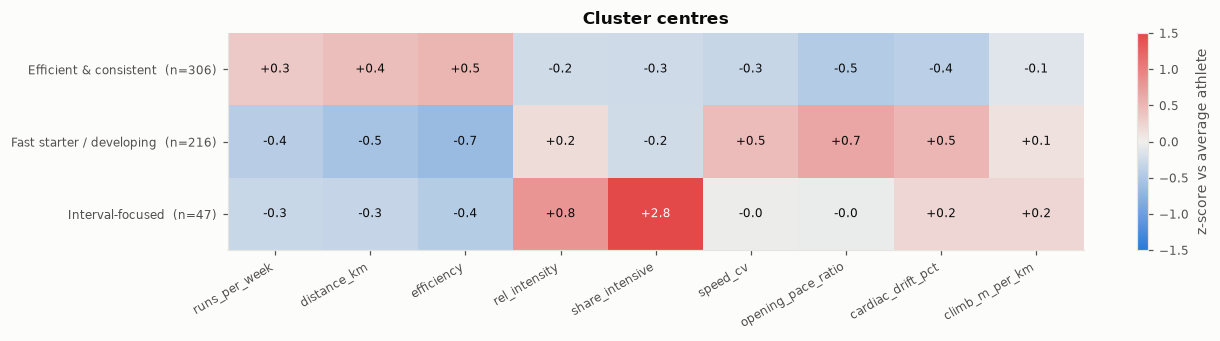

In [13]:
zp = zprof.rename(index=NAMES).loc[ORDER]
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(zp.values, cmap=DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(ORDER)), [f"{n}  (n={(core.profile == n).sum()})" for n in ORDER])
for r in range(zp.shape[0]):
    for c in range(zp.shape[1]):
        v = zp.iat[r, c]
        ax.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, label="z-score vs average athlete")
ax.set_title("Cluster centres")
fig.tight_layout()

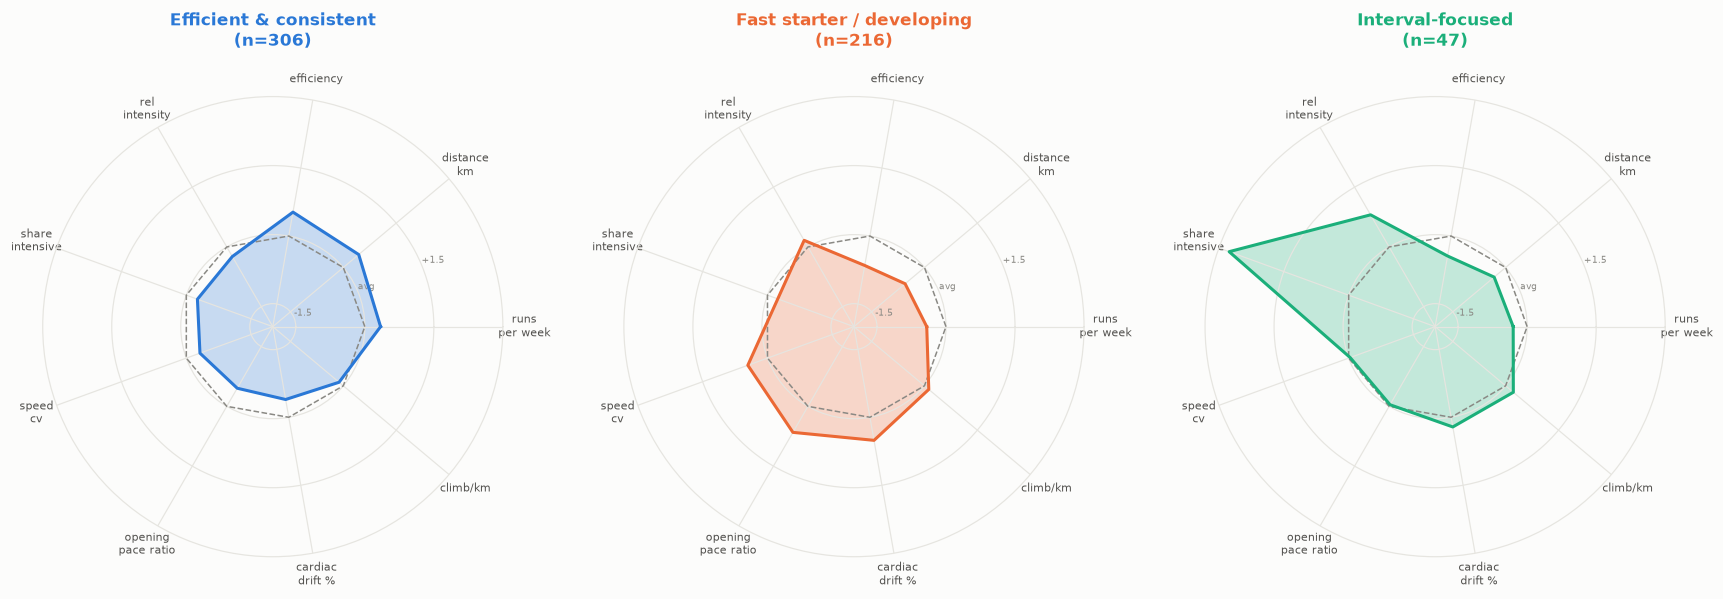

In [14]:
# Radar chart: the same centres as a "fingerprint" per profile. The grey ring = average athlete.
angles = np.linspace(0, 2 * np.pi, len(FEATURES), endpoint=False)
ang = np.r_[angles, angles[0]]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), subplot_kw=dict(polar=True))
for ax, name in zip(axes, ORDER):
    r = np.clip(zp.loc[name].values, -1.5, 3) + 2           # shift: 2 = average
    ax.plot(ang, np.full_like(ang, 2), color=MUTED, lw=1, ls="--")
    ax.fill(ang, np.r_[r, r[0]], color=COLOR[name], alpha=0.25)
    ax.plot(ang, np.r_[r, r[0]], color=COLOR[name], lw=2)
    ax.set_xticks(angles, [f.replace("_", " ").replace(" pct", " %").replace(" m per km", "/km")
                           .replace(" ", "\n", 1) for f in FEATURES], fontsize=7, color=INK2)
    ax.set_yticks([0.5, 2, 3.5], ["-1.5", "avg", "+1.5"], fontsize=6, color=MUTED)
    ax.set_ylim(0, 5)
    ax.set_title(f"{name}\n(n={(core.profile == name).sum()})", color=COLOR[name], pad=18)
    ax.spines["polar"].set_color(GRID)
fig.tight_layout()

The z-scores are abstract. Below are the same profiles in **real units**: each dot is one athlete, and the box shows the middle 50%.

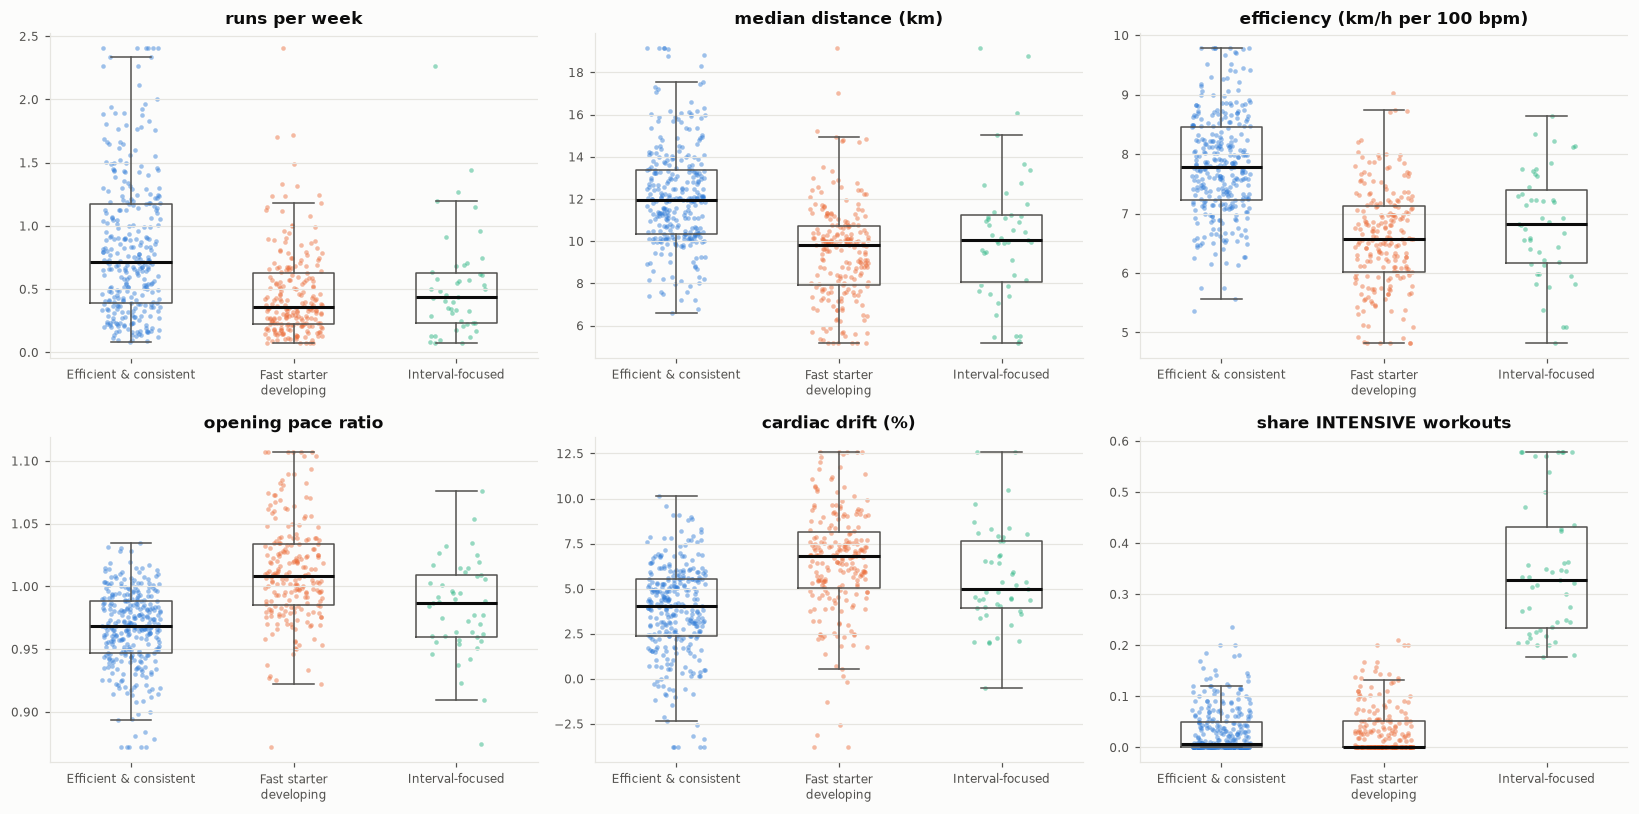

In [15]:
show = {
    "runs_per_week": "runs per week", "distance_km": "median distance (km)",
    "efficiency": "efficiency (km/h per 100 bpm)", "opening_pace_ratio": "opening pace ratio",
    "cardiac_drift_pct": "cardiac drift (%)", "share_intensive": "share INTENSIVE workouts",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
jit = np.random.default_rng(1)
for ax, (f, label) in zip(axes.flat, show.items()):
    data = [core.loc[core.profile == n, f] for n in ORDER]
    lo_, hi_ = core[f].quantile([0.01, 0.99])
    for i_, (n, d) in enumerate(zip(ORDER, data)):
        d = d.clip(lo_, hi_)
        ax.scatter(i_ + jit.uniform(-0.18, 0.18, len(d)), d, s=9, color=COLOR[n], alpha=0.45, lw=0)
    ax.boxplot([d.clip(lo_, hi_) for d in data], positions=range(3), widths=0.5, showfliers=False,
               medianprops=dict(color=INK, lw=2), boxprops=dict(color=INK2), whiskerprops=dict(color=INK2),
               capprops=dict(color=INK2))
    ax.set_xticks(range(3), [n.replace(" / ", "\n") for n in ORDER], fontsize=8)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
fig.tight_layout()

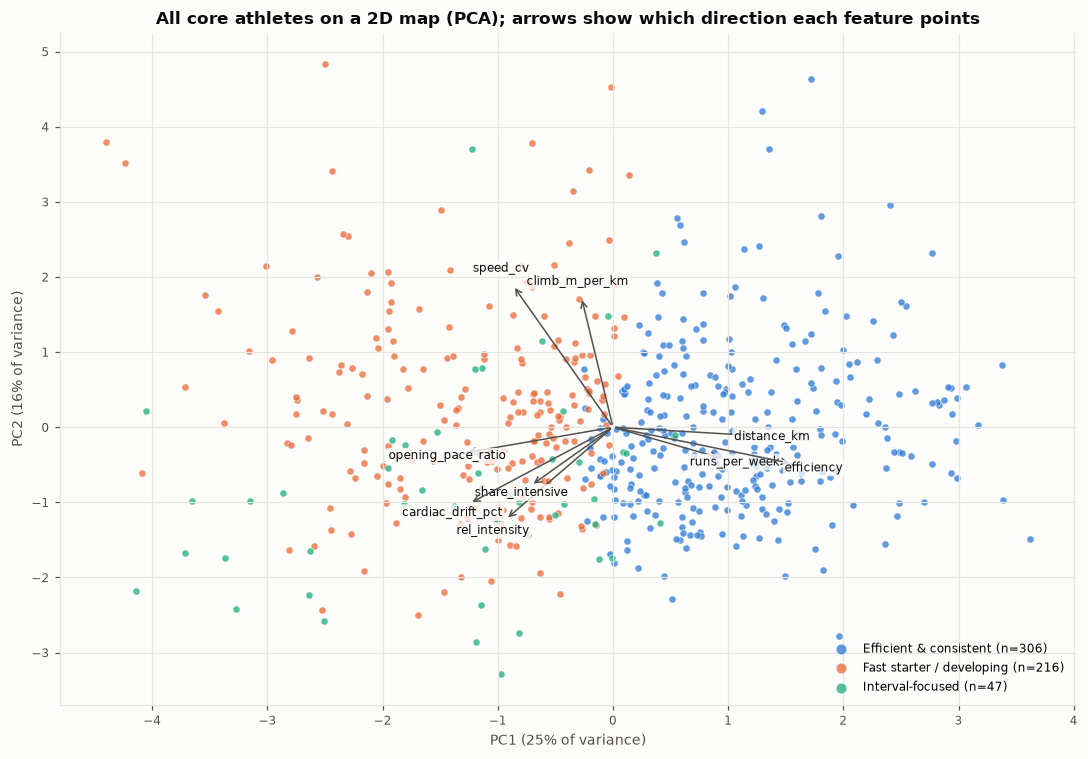

In [16]:
pca = PCA(2).fit(X)
P_core = pca.transform(X)
ev = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 7))
for n in ORDER:
    m = (core.profile == n).to_numpy()
    ax.scatter(P_core[m, 0], P_core[m, 1], s=22, color=COLOR[n], alpha=0.75, lw=0.5,
               edgecolor="#fcfcfb", label=f"{n} (n={m.sum()})")
for j, f in enumerate(FEATURES):
    vx, vy = pca.components_[:, j] * 3.2
    ax.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK2, lw=1))
    ax.text(vx * 1.12, vy * 1.12, f, fontsize=8, color=INK, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none", alpha=0.8))
ax.set(xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%} of variance)",
       title="All core athletes on a 2D map (PCA); arrows show which direction each feature points")
ax.legend(loc="lower right", markerscale=1.5)
fig.tight_layout()

## Step 8 · `km.predict`: assign the low-data athletes

The model is now fixed (3 centres). For the low-data athletes we compute the same features, apply the **same** scaler, and pick the nearest centre. Nothing is re-learned.

`km.transform` gives the distance to *every* centre. From that we compute a **margin**: `1 − d_nearest / d_second`.
* margin ≈ 0 → right between two profiles (uncertain)
* margin ≈ 1 → close to its own centre (certain)

profile
Fast starter / developing    112
Efficient & consistent        48
Interval-focused              32


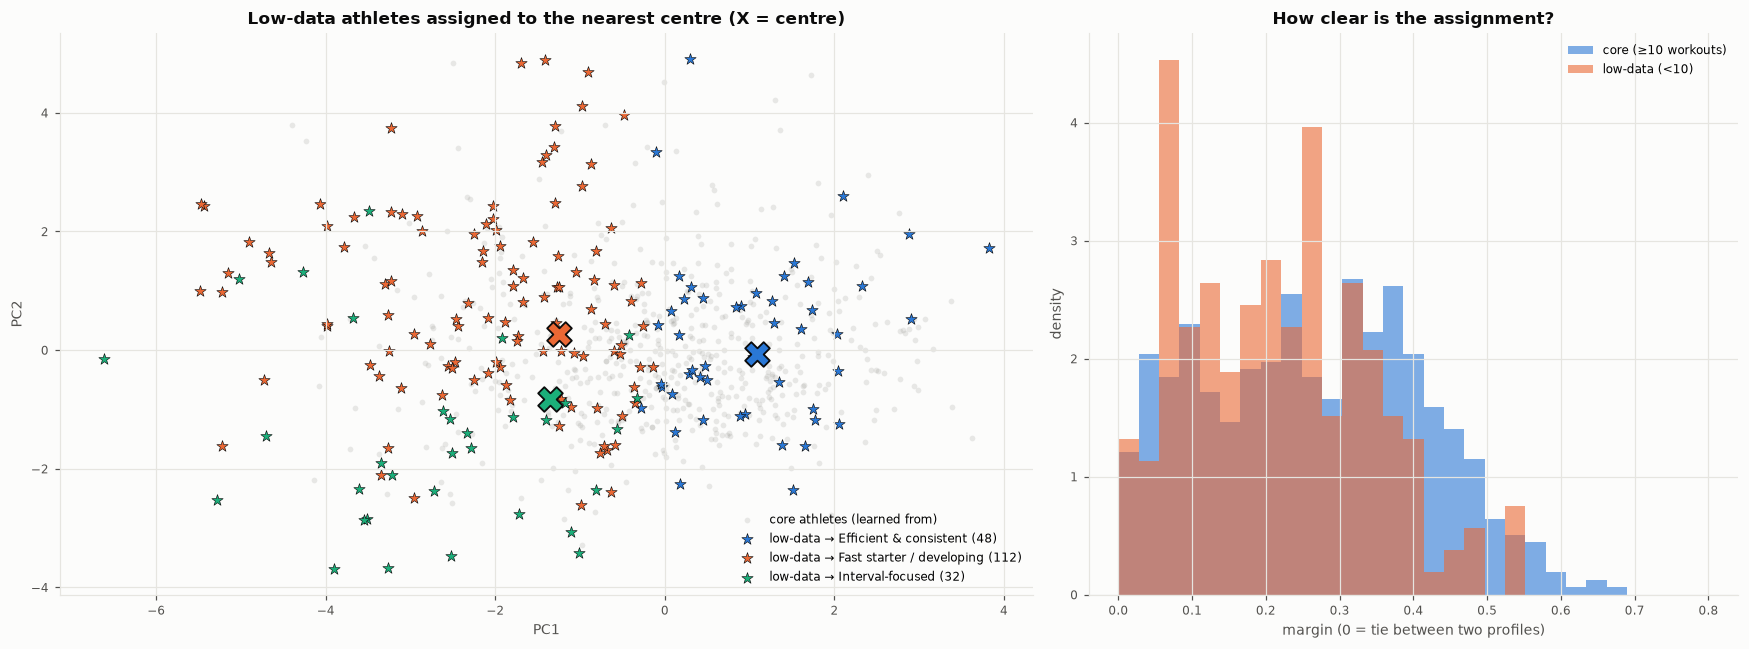

In [17]:
X_low = transform(low)
low["profile"] = pd.Categorical([NAMES[l] for l in km.predict(X_low)], categories=ORDER)

def margin(Xs):
    d = np.sort(km.transform(Xs), axis=1)
    return 1 - d[:, 0] / d[:, 1]

core["km_margin"], low["km_margin"] = margin(X), margin(X_low)
P_low = pca.transform(X_low)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
a1.scatter(P_core[:, 0], P_core[:, 1], s=14, color=MUTED, alpha=0.18, lw=0, label="core athletes (learned from)")
for n in ORDER:
    m = (low.profile == n).to_numpy()
    a1.scatter(P_low[m, 0], P_low[m, 1], s=60, marker="*", color=COLOR[n], edgecolor=INK, lw=0.4,
               label=f"low-data → {n} ({m.sum()})")
cent = pca.transform(km.cluster_centers_)
for c, (cx, cy) in enumerate(cent):
    a1.scatter(cx, cy, s=260, marker="X", color=COLOR[NAMES[c]], edgecolor=INK, lw=1.2, zorder=5)
a1.set(title="Low-data athletes assigned to the nearest centre (X = centre)", xlabel="PC1", ylabel="PC2")
a1.legend(loc="lower right")

bins = np.linspace(0, 0.8, 30)
a2.hist(core.km_margin, bins=bins, density=True, color=BLUE, alpha=0.6, label=f"core (≥{MIN_WORKOUTS} workouts)")
a2.hist(low.km_margin, bins=bins, density=True, color=ORANGE, alpha=0.6, label=f"low-data (<{MIN_WORKOUTS})")
a2.set(title="How clear is the assignment?", xlabel="margin (0 = tie between two profiles)", ylabel="density")
a2.legend()
fig.tight_layout()
print(low.profile.value_counts().to_string())

The low-data athletes lie further out on the map (more extreme feature values from few runs) and their margin is on average smaller. k-means still gives them a single hard label. For that reason we move to a model that expresses uncertainty.

## Step 9 · Gaussian mixture: probabilities instead of hard labels

A **Gaussian Mixture Model (GMM)** sees each profile as a (multidimensional) bell curve with its own centre *and* width per feature. `predict_proba` then gives each athlete a **probability per profile**, e.g. 70% efficient / 25% fast starter / 5% interval.

| | k-means | GMM |
|---|---|---|
| Output | 1 label | probability per profile |
| Cluster shape | round, all the same size | ellipses, any size |
| Choosing k | silhouette / elbow | BIC (statistical fit, lower = better) |

### 9a · A trap: a feature that is often exactly 0

45% of the core athletes have **exactly 0%** INTENSIVE workouts. A GMM can "cheat" with that: it builds a cluster around that one point with **variance ≈ 0** on `share_intensive`. Such a narrow bell curve gives probabilities of practically 100%, and the clustering then mostly learns "zero intensive workouts: yes or no".

The fix is `reg_covar`: a minimum variance per feature, so no cluster can become infinitely narrow.

Share of core athletes ≥ 80% certain: without reg_covar 92%, with reg_covar 73%


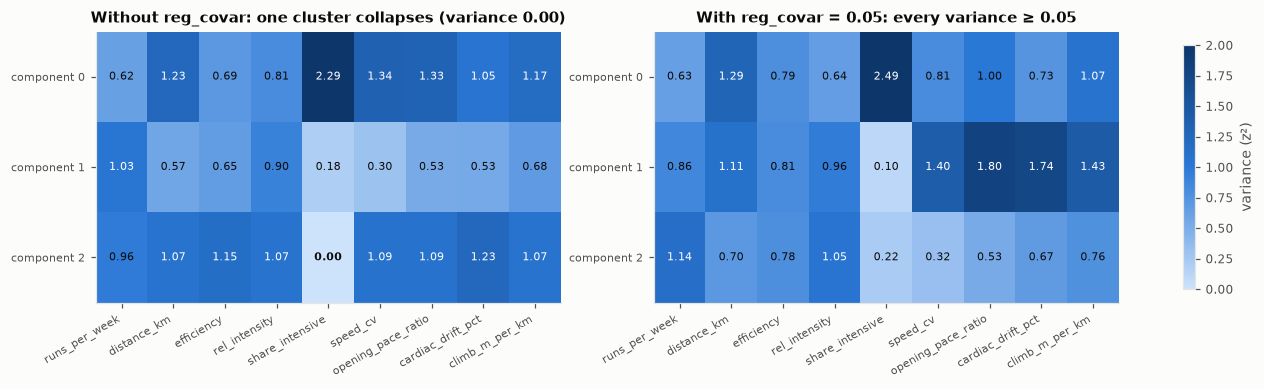

In [18]:
gmm_naive = GaussianMixture(K, covariance_type="diag", n_init=20, random_state=SEED).fit(X)
REG = 0.05
gmm = GaussianMixture(K, covariance_type="diag", reg_covar=REG, n_init=20, random_state=SEED).fit(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.2))
for ax, g_, title in [(axes[0], gmm_naive, "Without reg_covar: one cluster collapses (variance 0.00)"),
                      (axes[1], gmm, f"With reg_covar = {REG}: every variance ≥ {REG}")]:
    v = g_.covariances_
    im = ax.imshow(v, cmap=SEQUENTIAL, vmin=0, vmax=2, aspect="auto")
    for r in range(v.shape[0]):
        for c in range(v.shape[1]):
            ax.text(c, r, f"{v[r, c]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v[r, c] > 1 else INK, fontweight="bold" if v[r, c] < 0.01 else None)
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=30, ha="right", fontsize=7)
    ax.set_yticks(range(K), [f"component {i}" for i in range(K)], fontsize=7)
    ax.set_title(title, fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, label="variance (z²)", shrink=0.9)

p_naive = gmm_naive.predict_proba(X).max(1)
p_reg = gmm.predict_proba(X).max(1)
print(f"Share of core athletes ≥ 80% certain: without reg_covar {np.mean(p_naive >= .8):.0%}, "
      f"with reg_covar {np.mean(p_reg >= .8):.0%}")

### 9b · Choosing k with the BIC

The **BIC** rewards a good fit but penalises extra parameters. We compare three cluster shapes: *spherical* (round), *diag* (ellipse along the feature axes) and *full* (any tilted ellipse).

,spherical,diag,full
1,14602.0,14653.0,14264.0
2,14236.0,13910.0,13817.0
3,14133.0,13695.0,13904.0
4,14045.0,13678.0,14066.0
5,13989.0,13673.0,14285.0
6,13956.0,13724.0,14581.0
7,13952.0,13752.0,14787.0
8,13980.0,13808.0,15067.0


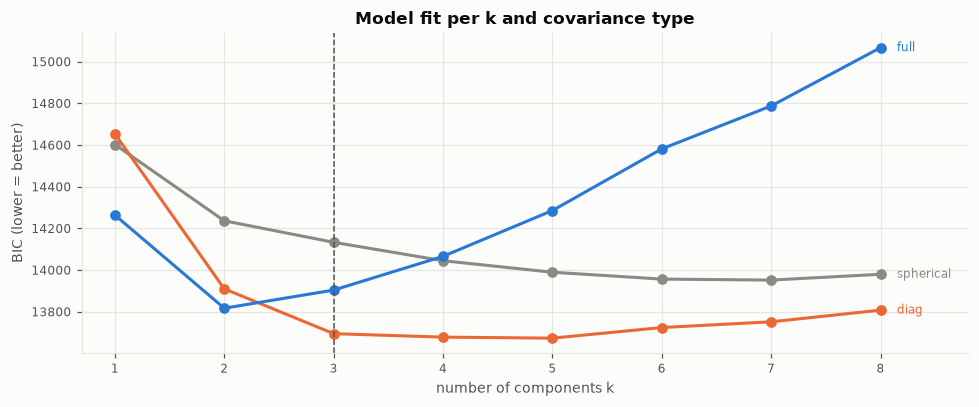

In [19]:
bic = {}
for cov in ["spherical", "diag", "full"]:
    bic[cov] = [GaussianMixture(k, covariance_type=cov, reg_covar=REG, n_init=5, random_state=SEED).fit(X).bic(X)
                for k in range(1, 9)]
bic = pd.DataFrame(bic, index=range(1, 9))

fig, ax = plt.subplots(figsize=(9, 3.8))
for cov, col in zip(bic.columns, [MUTED, ORANGE, BLUE]):
    ax.plot(bic.index, bic[cov], marker="o", ms=6, color=col, label=cov)
    ax.text(8.15, bic[cov].iloc[-1], cov, color=col, fontsize=8, va="center")
ax.axvline(K, color=INK2, ls="--", lw=1)
ax.set(xlabel="number of components k", ylabel="BIC (lower = better)", title="Model fit per k and covariance type",
       xlim=(0.7, 8.8))
fig.tight_layout()
bic.round(0)

We keep **k = 3, `diag`**, so we can compare directly with k-means. The GMM numbers its components arbitrarily, so we match them to the k-means profiles on the largest overlap (Hungarian matching).

### 9c · Does the GMM find the same profiles as k-means?

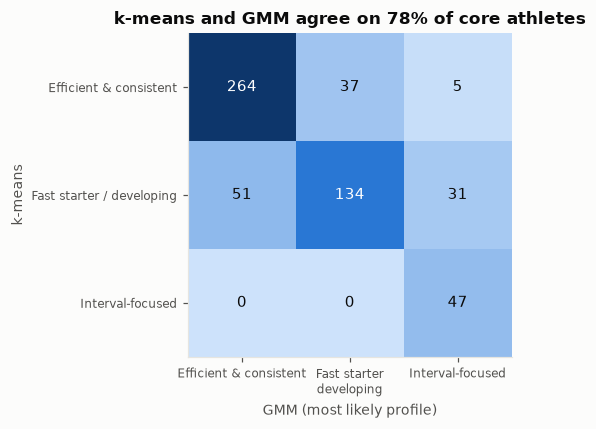

In [20]:
overlap = pd.crosstab(km.labels_, gmm.predict(X)).reindex(index=range(K), columns=range(K), fill_value=0)
rows_, cols_ = linear_sum_assignment(-overlap.values)
GMM_NAMES = {g_: NAMES[k_] for k_, g_ in zip(rows_, cols_)}
prob_cols = [GMM_NAMES[c] for c in range(K)]

ct = pd.crosstab(core.profile, pd.Categorical([GMM_NAMES[c] for c in gmm.predict(X)], categories=ORDER),
                 rownames=["k-means"], colnames=["GMM"], dropna=False)
agree = np.trace(ct.values) / ct.values.sum()

fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(ct.values, cmap=SEQUENTIAL)
ax.set_xticks(range(K), [n.replace(" / ", "\n") for n in ORDER], fontsize=8)
ax.set_yticks(range(K), ORDER, fontsize=8)
for r in range(K):
    for c in range(K):
        v = ct.iat[r, c]
        ax.text(c, r, v, ha="center", va="center", color="white" if v > ct.values.max() / 2 else INK, fontsize=10)
ax.set(xlabel="GMM (most likely profile)", ylabel="k-means")
ax.grid(False)
ax.set_title(f"k-means and GMM agree on {agree:.0%} of core athletes")
fig.tight_layout()

Largely the same, but not identical. Because the GMM may also fit the **width** of each cluster, it draws the boundaries differently from k-means (which only looks at the distance to the centre). The *Interval-focused* profile is the most stable. The boundary between *efficient* and *fast starter* is a sliding scale, and the two models cut it in different places. That fits the low silhouette from step 6.

### 9d · Probability ≠ fit: add typicality

`predict_proba` answers *"which profile fits best **relatively**?"*. An athlete far away from **all** profiles still gets ~100% for the nearest/widest one. So we add a second measure:

* **certainty** = highest profile probability (`predict_proba`)
* **typicality** = how likely the athlete is under the *whole* model (`score_samples`), expressed as a percentile of the core athletes. Below the 5th percentile = **atypical**: this athlete doesn't really look like any profile.

Combined into one label per athlete:

| status | rule |
|---|---|
| **confident** | typical *and* ≥ 80% for one profile |
| **between profiles** | typical, but < 80% (a mixed profile) |
| **atypical** | typicality < 5th percentile; the profile is a guess |

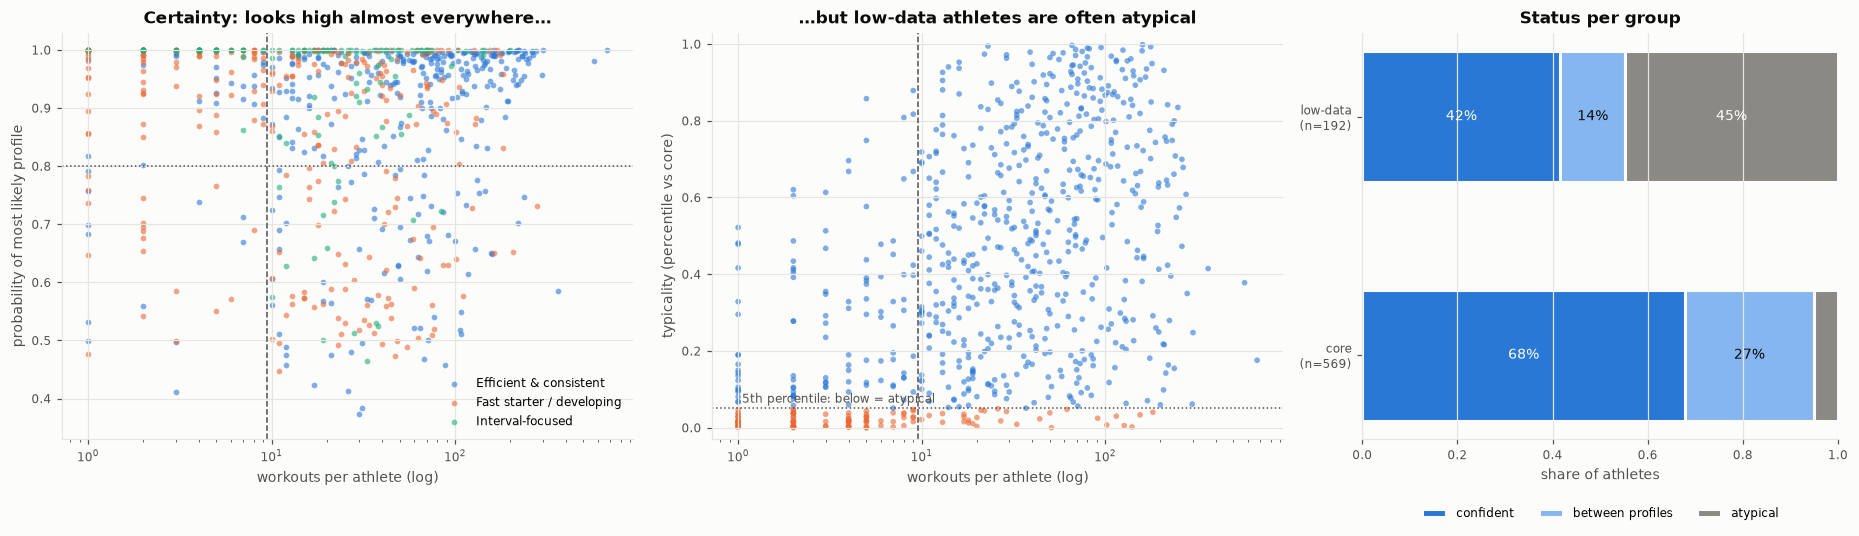

In [21]:
everyone = pd.concat([core.assign(group="core"), low.assign(group="low-data")])
X_all = transform(everyone)
proba = pd.DataFrame(gmm.predict_proba(X_all), index=everyone.index, columns=prob_cols)[ORDER]
everyone[ORDER] = proba.values
everyone["gmm_profile"] = pd.Categorical(proba.idxmax(axis=1), categories=ORDER)
everyone["certainty"] = proba.max(axis=1)

ll_core = np.sort(gmm.score_samples(X))
everyone["typicality"] = np.searchsorted(ll_core, gmm.score_samples(X_all)) / len(ll_core)
STATUS = ["confident", "between profiles", "atypical"]
everyone["status"] = pd.Categorical(np.select(
    [everyone.typicality < 0.05, everyone.certainty >= 0.8], ["atypical", "confident"], "between profiles"),
    categories=STATUS)
STATUS_STYLE = {"confident": BLUE, "between profiles": "#86b6ef", "atypical": MUTED}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
a1, a2, a3 = axes
for n in ORDER:
    m = everyone.gmm_profile == n
    a1.scatter(everyone.workouts[m], everyone.certainty[m], s=14, color=COLOR[n], alpha=0.6, lw=0, label=n)
a1.axhline(0.8, color=INK2, ls=":", lw=1)
a1.set(xscale="log", xlabel="workouts per athlete (log)", ylabel="probability of most likely profile",
       title="Certainty: looks high almost everywhere…", ylim=(0.33, 1.03))
a1.legend(loc="lower right")

col = np.where(everyone.typicality < 0.05, ORANGE, BLUE)
a2.scatter(everyone.workouts, everyone.typicality, s=14, c=col, alpha=0.6, lw=0)
a2.axhline(0.05, color=INK2, ls=":", lw=1)
a2.text(1.05, 0.065, "5th percentile: below = atypical", fontsize=8, color=INK2)
a2.set(xscale="log", xlabel="workouts per athlete (log)", ylabel="typicality (percentile vs core)",
       title="…but low-data athletes are often atypical", ylim=(-0.03, 1.03))
for a_ in (a1, a2):
    a_.axvline(MIN_WORKOUTS - 0.5, color=INK2, ls="--", lw=1)

st = everyone.groupby(["group", "status"], observed=False).size().unstack()
st_pct = st.div(st.sum(axis=1), axis=0)
left = np.zeros(len(st))
for s_ in STATUS:
    v = st_pct[s_].values
    a3.barh(st.index, v, left=left, color=STATUS_STYLE[s_], edgecolor="#fcfcfb", lw=2, height=0.55, label=s_)
    for yi, (l_, v_) in enumerate(zip(left, v)):
        if v_ > 0.07:
            a3.text(l_ + v_ / 2, yi, f"{v_:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if s_ != "between profiles" else INK)
    left += v
a3.set(xlim=(0, 1), xlabel="share of athletes", title="Status per group")
a3.set_yticks(range(len(st)), [f"{g_}\n(n={int(st.loc[g_].sum())})" for g_ in st.index])
a3.grid(axis="y", visible=False)
a3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
fig.tight_layout()

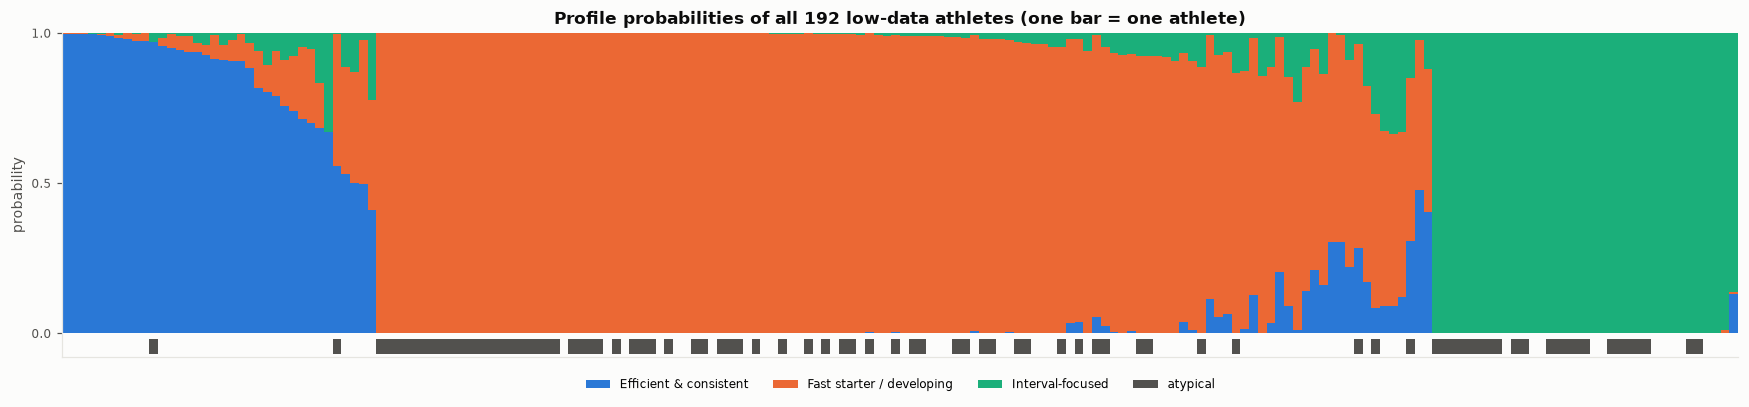

In [22]:
# Probability bars: every low-data athlete as one bar, sorted by profile and certainty.
# A grey strip underneath marks atypical athletes.
lowp = everyone[everyone.group == "low-data"].sort_values(["gmm_profile", "certainty"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(16, 3.8))
bottom = np.zeros(len(lowp))
xs = np.arange(len(lowp))
for n in ORDER:
    ax.bar(xs, lowp[n], bottom=bottom, color=COLOR[n], width=1.0, lw=0, label=n)
    bottom += lowp[n].values
aty = (lowp.status == "atypical").to_numpy()
ax.bar(xs[aty], 0.05, bottom=-0.07, color=INK2, width=1.0, lw=0, label="atypical")
ax.set(xlim=(-0.5, len(lowp) - 0.5), ylim=(-0.08, 1), xticks=[], yticks=[0, 0.5, 1], ylabel="probability",
       title=f"Profile probabilities of all {len(lowp)} low-data athletes (one bar = one athlete)")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=4)
fig.tight_layout()

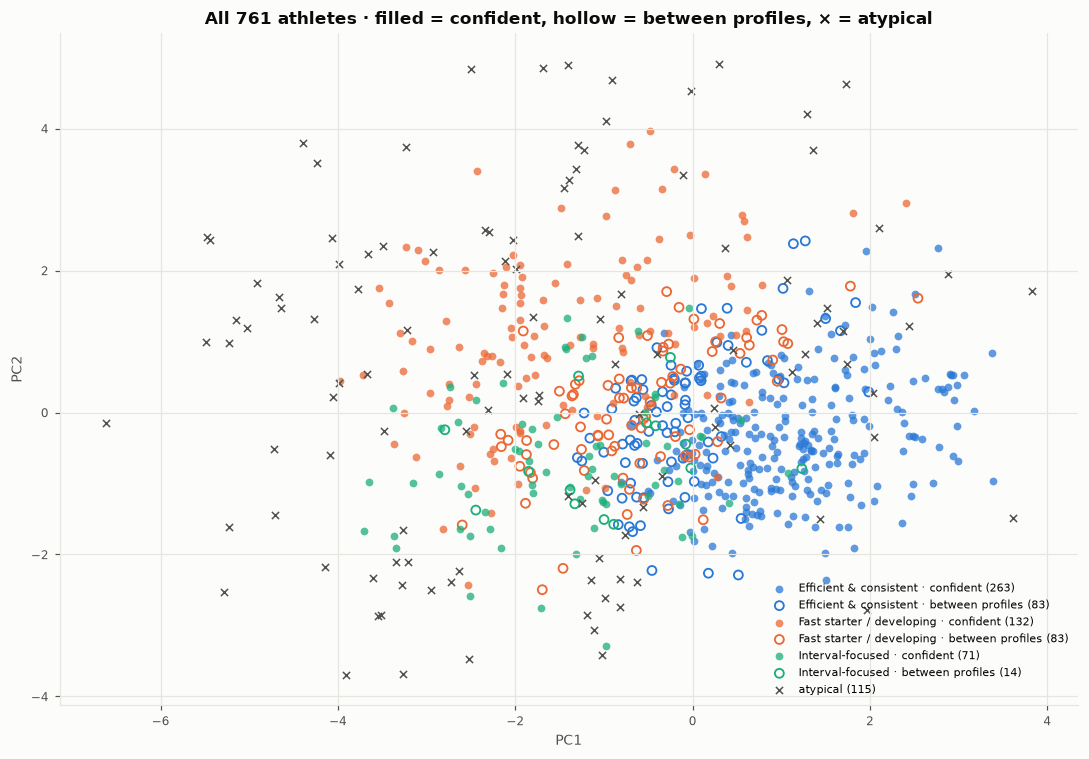

In [23]:
# The map again, now for everyone: colour = profile, hollow = between profiles, grey cross = atypical.
P_all = pca.transform(X_all)
fig, ax = plt.subplots(figsize=(10, 7))
for n in ORDER:
    for s_, kw in [("confident", dict(s=26, alpha=0.75, lw=0)),
                   ("between profiles", dict(s=34, facecolor="none", lw=1.2))]:
        m = ((everyone.gmm_profile == n) & (everyone.status == s_)).to_numpy()
        colorkw = {"edgecolor": COLOR[n]} if s_ != "confident" else {"color": COLOR[n]}
        ax.scatter(P_all[m, 0], P_all[m, 1], **kw, **colorkw,
                   label=f"{n} · {s_} ({m.sum()})")
m = (everyone.status == "atypical").to_numpy()
ax.scatter(P_all[m, 0], P_all[m, 1], s=22, marker="x", color=INK2, lw=1, label=f"atypical ({m.sum()})")
ax.set(xlabel="PC1", ylabel="PC2", title="All 761 athletes · filled = confident, hollow = between profiles, × = atypical")
ax.legend(loc="lower right", fontsize=7)
fig.tight_layout()

## Step 10 · Profile cards

What does this look like for an individual athlete? Four examples: the most typical athlete per profile, plus one athlete *between profiles*. Left are the probabilities, right is how the athlete differs from the average (z-score), with the profile centre as a dashed outline.

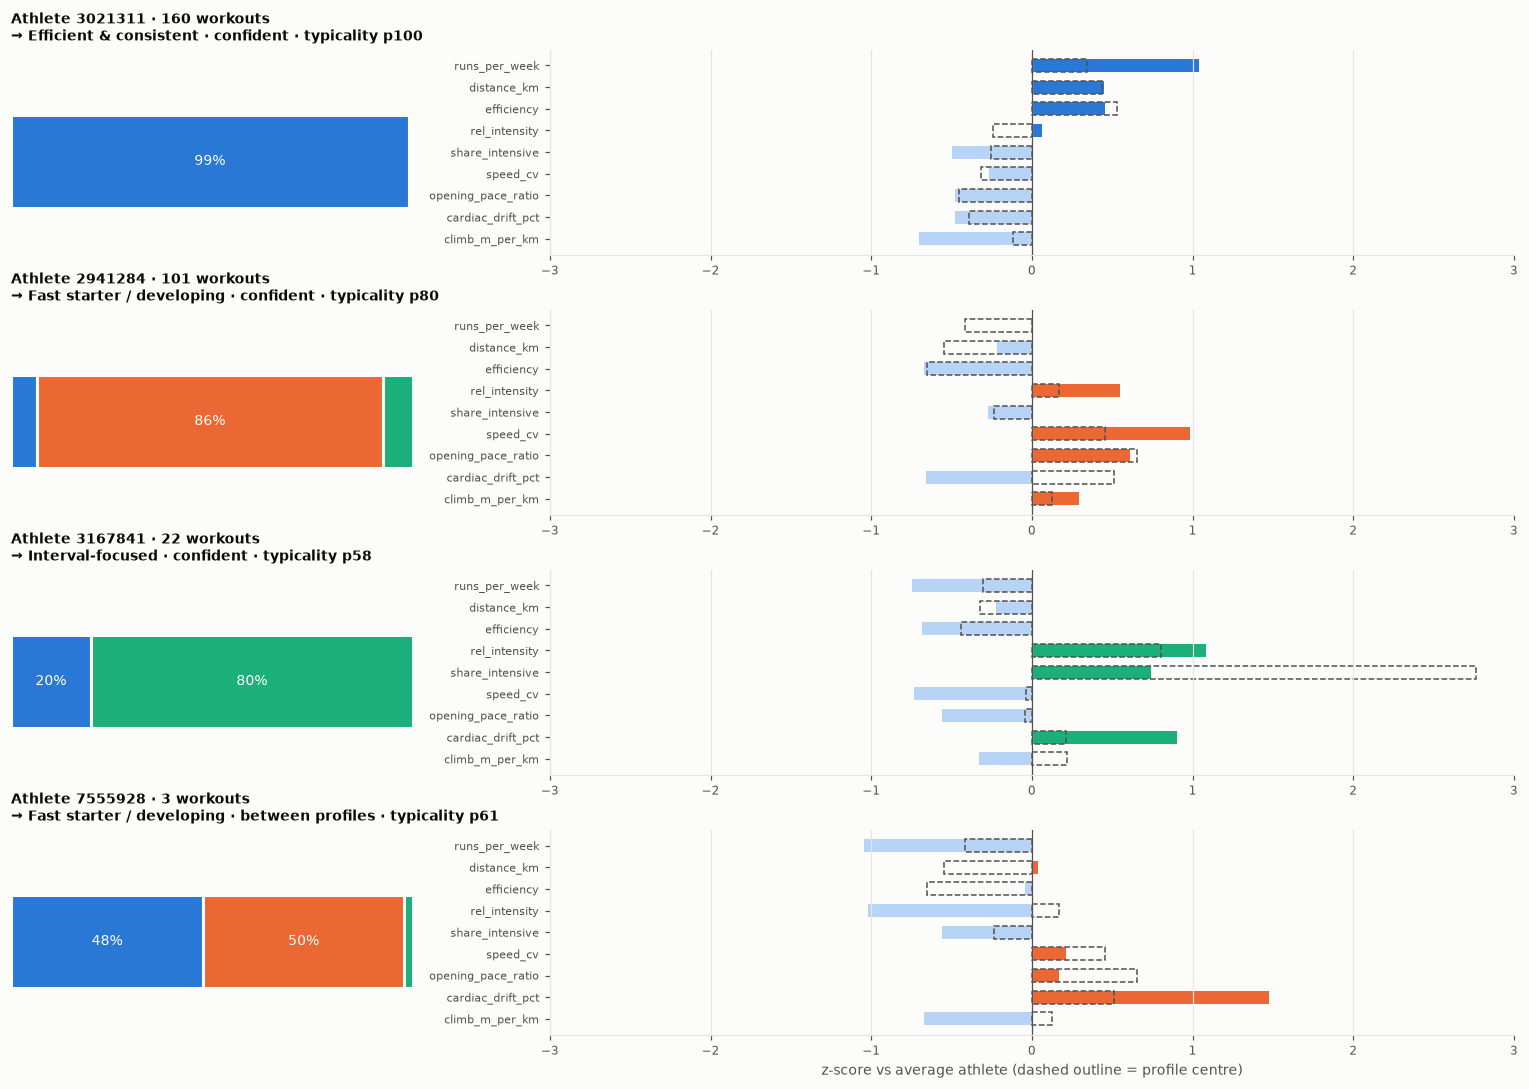

In [24]:
picks = [everyone[(everyone.status == "confident") & (everyone.gmm_profile == n)].typicality.idxmax() for n in ORDER]
between = everyone[everyone.status == "between profiles"]
picks.append((between.certainty - 0.5).abs().idxmin())
Z = pd.DataFrame(X_all, index=everyone.index, columns=FEATURES)

fig, axes = plt.subplots(len(picks), 2, figsize=(14, 2.5 * len(picks)),
                         gridspec_kw={"width_ratios": [1, 2.4]})
for (ax_p, ax_z), uid in zip(axes, picks):
    row = everyone.loc[uid]
    left_ = 0
    for n in ORDER:
        ax_p.barh(0, row[n], left=left_, color=COLOR[n], edgecolor="#fcfcfb", lw=2, height=0.5)
        if row[n] > 0.12:
            ax_p.text(left_ + row[n] / 2, 0, f"{row[n]:.0%}", ha="center", va="center", color="white", fontsize=9)
        left_ += row[n]
    ax_p.set(xlim=(0, 1), ylim=(-0.5, 0.6), yticks=[], xticks=[])
    ax_p.grid(False)
    for s in ax_p.spines.values():
        s.set_visible(False)
    ax_p.set_title(f"Athlete {uid} · {int(row.workouts)} workouts\n"
                   f"→ {row.gmm_profile} · {row.status} · typicality p{100 * row.typicality:.0f}",
                   loc="left", fontsize=9, color=INK)

    z = Z.loc[uid].clip(-3, 3)
    ax_z.barh(FEATURES, z, color=[COLOR[row.gmm_profile] if v > 0 else "#b7d3f6" for v in z], height=0.6)
    ax_z.barh(FEATURES, zp.loc[row.gmm_profile].clip(-3, 3), fill=False, edgecolor=INK2, lw=1, height=0.6, ls="--")
    ax_z.axvline(0, color=INK2, lw=0.8)
    ax_z.set(xlim=(-3, 3))
    ax_z.tick_params(axis="y", labelsize=7)
    ax_z.invert_yaxis()
    ax_z.grid(axis="y", visible=False)
axes[-1, 1].set_xlabel("z-score vs average athlete (dashed outline = profile centre)")
fig.tight_layout()

## Step 11 · Validation: are the profiles stable over time?

The clustering always finds *some* groups, even in noise. The question is whether a profile says something about the **runner**. If so, an athlete should get roughly the same profile in a different period.

**Setup:**
1. Take athletes with **≥ 20 workouts**, so each half has at least 10 (the same minimum as before).
2. Split each athlete's workouts **chronologically**: first half (early) and second half (late).
3. Fit the **whole pipeline** (log, clip, scaler, k-means) **on the early halves only**. The model never sees the late data.
4. Assign each athlete a profile on the early half and on the late half with that model, and compare.

**Two reference points**, so the outcome means something:
* **Random split** (workouts alternately to A/B, interleaved in time): both halves cover the same period, so differences come only from *measurement noise*. This is the upper limit of what's achievable.
* **Chance:** shuffle the late profiles randomly across athletes (1,000 times). That's the agreement you get when profiles say *nothing* about the runner.

The chronological split lands somewhere between them: noise + real change over time.

441 athletes, 37,641 workouts · median time between the centre of early and late: 11.3 months


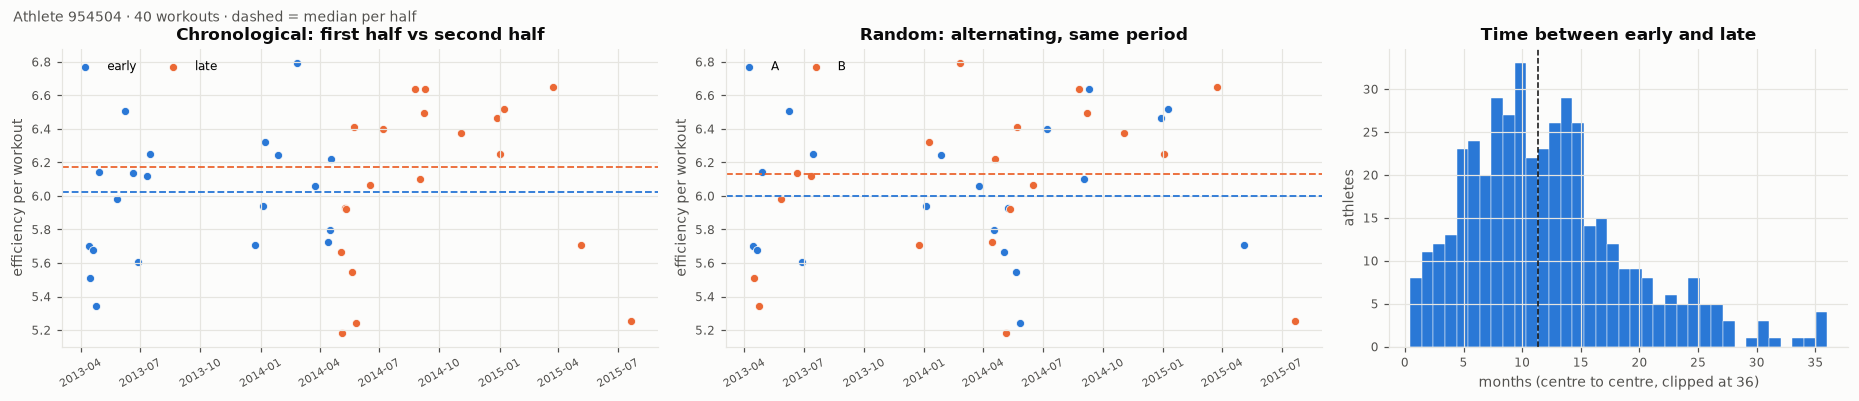

In [25]:
MIN_HALF = 10
ws = w.sort_values(["user_id", "date"]).copy()
ws["rank"] = ws.groupby("user_id").cumcount()
ws["n"] = ws.groupby("user_id")["user_id"].transform("size")
ws = ws[ws.n >= 2 * MIN_HALF]
ws["half"] = np.where(ws["rank"] < ws.n // 2, "early", "late")
ws["alt"] = np.where(ws["rank"] % 2 == 0, "A", "B")

splits = {
    "chronological": (athlete_table(ws[ws.half == "early"]), athlete_table(ws[ws.half == "late"])),
    "random (interleaved)": (athlete_table(ws[ws.alt == "A"]), athlete_table(ws[ws.alt == "B"])),
}
e_, l_ = splits["chronological"]
gap_months = (ws[ws.half == "late"].groupby("user_id").date.median()
              - ws[ws.half == "early"].groupby("user_id").date.median()).dt.days / 30.4
print(f"{ws.user_id.nunique()} athletes, {len(ws):,} workouts · "
      f"median time between the centre of early and late: {gap_months.median():.1f} months")

# Illustration: one athlete, both ways of splitting.
uid = ws.groupby("user_id").size().sub(40).abs().idxmin()
one = ws[ws.user_id == uid]
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for ax, col, groups, title in [(a1, "half", {"early": BLUE, "late": ORANGE}, "Chronological: first half vs second half"),
                               (a2, "alt", {"A": BLUE, "B": ORANGE}, "Random: alternating, same period")]:
    for gname, c in groups.items():
        sub = one[one[col] == gname]
        ax.scatter(sub.date, sub.efficiency, s=28, color=c, label=gname, edgecolor="#fcfcfb", lw=0.5)
        ax.axhline(sub.efficiency.median(), color=c, ls="--", lw=1.2)
    ax.set(title=title, ylabel="efficiency per workout")
    ax.legend(loc="upper left", ncol=2)
    ax.tick_params(axis="x", labelsize=7, rotation=30)
fig.text(0.01, 1.0, f"Athlete {uid} · {len(one)} workouts · dashed = median per half", fontsize=9, color=INK2, va="top")
a3.hist(gap_months.clip(upper=36), bins=36, color=BLUE, edgecolor="#fcfcfb", lw=0.3)
a3.axvline(gap_months.median(), color=INK, ls="--", lw=1)
a3.set(title="Time between early and late", xlabel="months (centre to centre, clipped at 36)", ylabel="athletes")
fig.tight_layout()

### 11a · Which features are a stable "trait" of a runner?

First per feature: how strongly do an athlete's early and late values correlate (Spearman ρ, a *test-retest* correlation)? High = the feature describes the runner. Low = it mostly measures noise or changes a lot over time.

,chronological,random (interleaved)
share_intensive,0.57,0.70
rel_intensity,0.66,0.78
cardiac_drift_pct,0.66,0.82
opening_pace_ratio,0.65,0.82
distance_km,0.72,0.87
speed_cv,0.74,0.89
climb_m_per_km,0.78,0.94
runs_per_week,0.34,0.95
efficiency,0.94,0.99


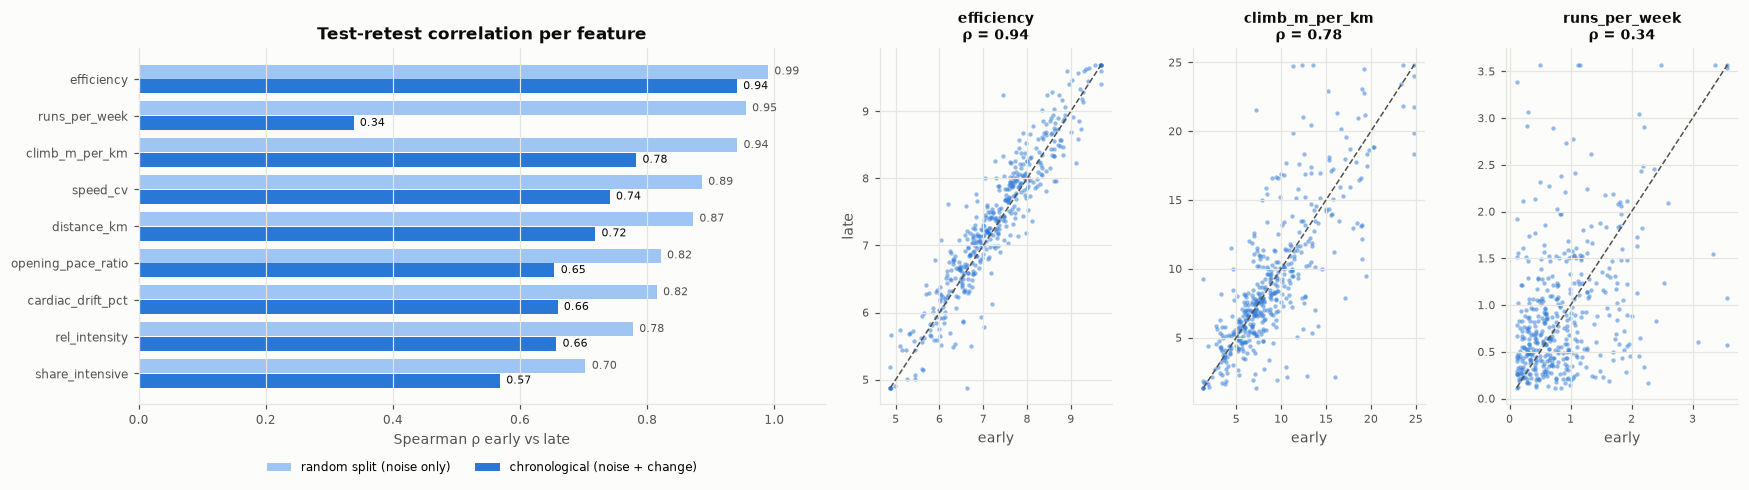

In [26]:
retest = pd.DataFrame({
    name: {f: a[f].corr(b.loc[a.index, f], method="spearman") for f in FEATURES}
    for name, (a, b) in splits.items()
}).sort_values("random (interleaved)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
y = np.arange(len(retest))
a1.barh(y + 0.2, retest["random (interleaved)"], height=0.38, color="#9ec5f4", label="random split (noise only)")
a1.barh(y - 0.2, retest["chronological"], height=0.38, color=BLUE, label="chronological (noise + change)")
for yi, (r_, c_) in enumerate(zip(retest["random (interleaved)"], retest["chronological"])):
    a1.text(r_ + 0.01, yi + 0.2, f"{r_:.2f}", va="center", fontsize=7, color=INK2)
    a1.text(c_ + 0.01, yi - 0.2, f"{c_:.2f}", va="center", fontsize=7, color=INK)
a1.set_yticks(y, retest.index, fontsize=8)
a1.set(xlim=(0, 1.08), xlabel="Spearman ρ early vs late", title="Test-retest correlation per feature")
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
a1.grid(axis="y", visible=False)

# Scatter of the two most and the least stable feature (chronological).
order_ = retest["chronological"].sort_values()
show_f = [order_.index[-1], order_.index[-2], order_.index[0]]
inner = a2.get_subplotspec().subgridspec(1, 3, wspace=0.35)
a2.remove()
for k_, f in enumerate(show_f):
    ax = fig.add_subplot(inner[k_])
    x_, y_ = e_[f], l_.loc[e_.index, f]
    lo_, hi_ = pd.concat([x_, y_]).quantile([0.01, 0.99])
    ax.scatter(x_.clip(lo_, hi_), y_.clip(lo_, hi_), s=8, color=BLUE, alpha=0.5, lw=0)
    ax.plot([lo_, hi_], [lo_, hi_], color=INK2, ls="--", lw=1)
    ax.set(title=f"{f}\nρ = {retest.loc[f, 'chronological']:.2f}", xlabel="early", ylabel="late" if k_ == 0 else None)
    ax.title.set_fontsize(9)
    ax.tick_params(labelsize=7)
fig.tight_layout()
retest.round(2)

### 11b · Do athletes keep their profile?

The model is fit on the early halves only. Each athlete then gets a profile on both halves. The heatmaps show where athletes from each early profile end up (per row, 100%).

,same profile,ARI,chance (95% interval)
chronological,73%,0.36,30%–39%
random (interleaved),89%,0.67,37%–45%


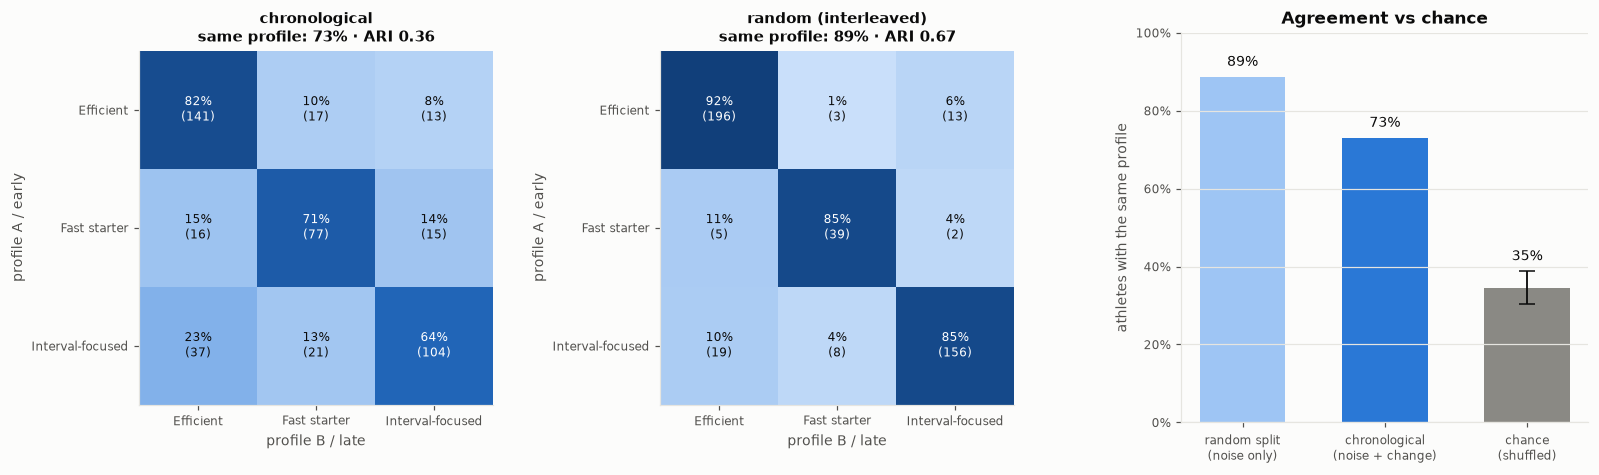

In [27]:
def fit_on(a: pd.DataFrame):
    # The full pipeline from steps 5–7, fit only on table `a`; returns a predict function.
    Xr = prepare(a)
    lo_, hi_ = Xr.quantile(0.01), Xr.quantile(0.99)
    sc = StandardScaler().fit(Xr.clip(lo_, hi_, axis=1))
    tf = lambda b: sc.transform(prepare(b).clip(lo_, hi_, axis=1))
    km_ = KMeans(K, n_init=50, random_state=SEED).fit(tf(a))
    names_ = name_clusters(pd.DataFrame(tf(a), columns=FEATURES).groupby(km_.labels_).mean())
    return lambda b: pd.Series(pd.Categorical([names_[l] for l in km_.predict(tf(b))], categories=ORDER),
                               index=b.index)

rng = np.random.default_rng(SEED)
stab = {}
for name, (a, b) in splits.items():
    predict = fit_on(a)
    pa, pb = predict(a), predict(b.loc[a.index])
    agree_ = (pa == pb).mean()
    perm = np.array([(pa.to_numpy() == rng.permutation(pb.to_numpy())).mean() for _ in range(1000)])
    stab[name] = dict(pa=pa, pb=pb, agree=agree_, ari=adjusted_rand_score(pa, pb), perm=perm)

fig = plt.figure(figsize=(17, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15], wspace=0.45)
for k_, (name, s) in enumerate(stab.items()):
    ax = fig.add_subplot(gs[k_])
    tm = pd.crosstab(s["pa"], s["pb"], normalize="index", dropna=False).reindex(index=ORDER, columns=ORDER, fill_value=0)
    cnt = pd.crosstab(s["pa"], s["pb"], dropna=False).reindex(index=ORDER, columns=ORDER, fill_value=0)
    ax.imshow(tm.values, cmap=SEQUENTIAL, vmin=0, vmax=1)
    for r in range(K):
        for c in range(K):
            v = tm.iat[r, c]
            ax.text(c, r, f"{v:.0%}\n({cnt.iat[r, c]})", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.5 else INK)
    short = [n.split(" ")[0].replace("Fast", "Fast starter") for n in ORDER]
    ax.set_xticks(range(K), short, fontsize=8)
    ax.set_yticks(range(K), short, fontsize=8)
    ax.set(xlabel="profile B / late", ylabel="profile A / early")
    ax.grid(False)
    ax.set_title(f"{name}\nsame profile: {s['agree']:.0%} · ARI {s['ari']:.2f}", fontsize=10)

ax = fig.add_subplot(gs[2])
chance = stab["chronological"]["perm"]
bars = {"random split\n(noise only)": stab["random (interleaved)"]["agree"],
        "chronological\n(noise + change)": stab["chronological"]["agree"],
        "chance\n(shuffled)": chance.mean()}
cols = ["#9ec5f4", BLUE, MUTED]
b_ = ax.bar(list(bars), list(bars.values()), color=cols, width=0.6)
ax.errorbar(2, chance.mean(), yerr=[[chance.mean() - np.percentile(chance, 2.5)],
                                    [np.percentile(chance, 97.5) - chance.mean()]],
            color=INK, capsize=5, lw=1.2)
for xi, v in enumerate(bars.values()):
    top = np.percentile(chance, 97.5) if xi == 2 else v
    ax.text(xi, top + 0.02, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set(ylim=(0, 1), ylabel="athletes with the same profile", title="Agreement vs chance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=8)

pd.DataFrame({k: {"same profile": f"{v['agree']:.0%}", "ARI": round(v["ari"], 2),
                  "chance (95% interval)": f"{np.percentile(v['perm'], 2.5):.0%}–{np.percentile(v['perm'], 97.5):.0%}"}
              for k, v in stab.items()}).T

### 11c · Is a change of profile a real change?

Some athletes switch profiles between early and late. If that's real (and not noise), their **features should change in the matching direction**. Example: someone going from *fast starter* to *efficient* should actually become more efficient and drift less.

,efficiency,cardiac_drift_pct,distance_km,runs_per_week
stays Efficient,0.12,0.06,-0.12,0.06
Fast starter → Efficient,0.50,-0.90,0.81,0.32
Efficient → Fast starter,-0.07,0.29,-1.35,-0.03
stays Fast starter,0.14,0.04,0.17,0.12


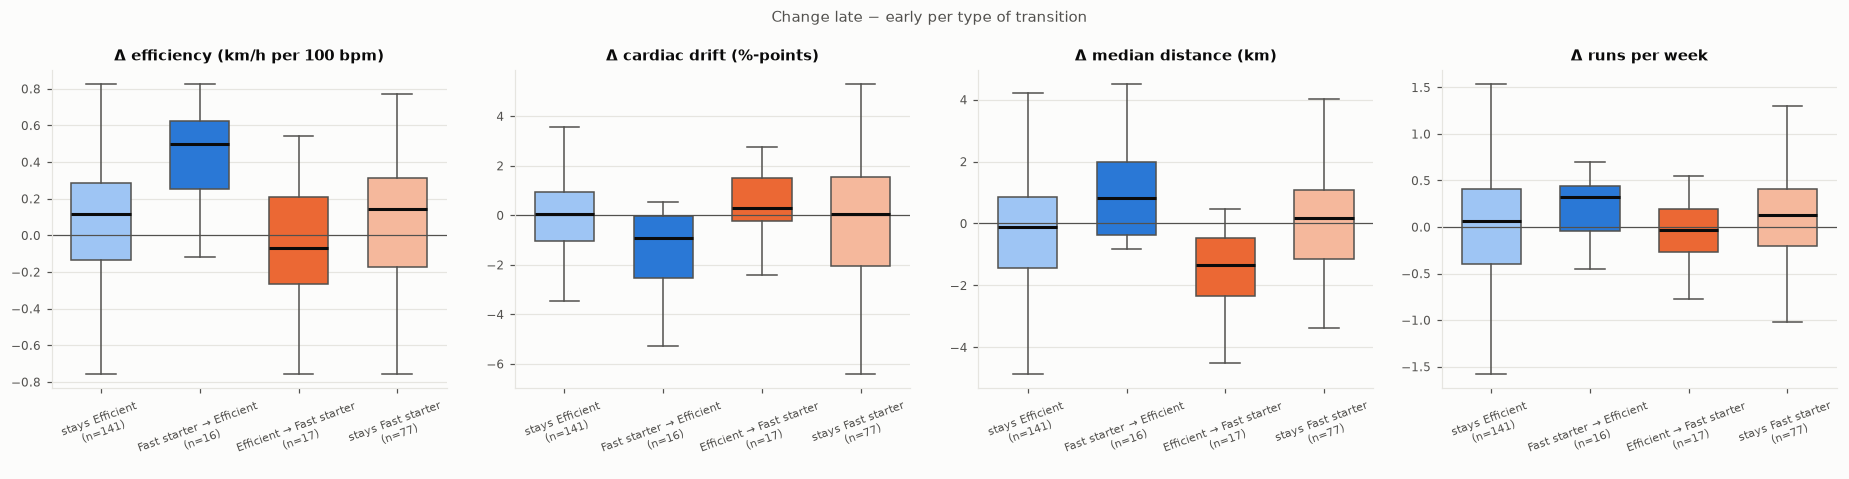

In [28]:
s = stab["chronological"]
delta = (l_.loc[e_.index, FEATURES] - e_[FEATURES])
trans = (s["pa"].astype(str) + " → " + s["pb"].astype(str))
groups_ = {
    "stays Efficient": "Efficient & consistent → Efficient & consistent",
    "Fast starter → Efficient": "Fast starter / developing → Efficient & consistent",
    "Efficient → Fast starter": "Efficient & consistent → Fast starter / developing",
    "stays Fast starter": "Fast starter / developing → Fast starter / developing",
}
gcol = {"stays Efficient": "#9ec5f4", "Fast starter → Efficient": BLUE,
        "Efficient → Fast starter": ORANGE, "stays Fast starter": "#f5b89c"}
show_d = {"efficiency": "Δ efficiency (km/h per 100 bpm)", "cardiac_drift_pct": "Δ cardiac drift (%-points)",
          "distance_km": "Δ median distance (km)", "runs_per_week": "Δ runs per week"}

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (f, label) in zip(axes, show_d.items()):
    data = [delta.loc[trans == t, f].dropna() for t in groups_.values()]
    lo_, hi_ = delta[f].quantile([0.02, 0.98])
    bp = ax.boxplot([d.clip(lo_, hi_) for d in data], positions=range(4), widths=0.6, showfliers=False,
                    patch_artist=True, medianprops=dict(color=INK, lw=2), whiskerprops=dict(color=INK2),
                    capprops=dict(color=INK2))
    for patch, gname in zip(bp["boxes"], groups_):
        patch.set(facecolor=gcol[gname], edgecolor=INK2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(4), [f"{g_}\n(n={len(d)})" for g_, d in zip(groups_, data)], fontsize=7, rotation=20)
    ax.set_title(label, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Change late − early per type of transition", fontsize=10, color=INK2)
fig.tight_layout()
delta.groupby(trans).median()[list(show_d)].loc[list(groups_.values())].set_axis(list(groups_)).round(2)

### 11d · Conclusion of the validation

| | same profile | ARI |
|---|---|---|
| Chance (shuffled) | ~35% (95%: 30–39%) | 0 |
| **Chronological** (~11 months apart) | **73%** | 0.36 |
| Random split (noise only) | 89% | 0.67 |

* **The profiles are a stable trait of the runner.** Over a gap of almost a year, 73% of athletes keep their profile, roughly twice as often as chance. The model was fit only on the early data, so this isn't leakage.
* **Measurement noise is small.** With two halves from the *same* period, 89% match. The gap between 89% and 73% is mostly real change over time.
* **Changes are real changes (11c).** Athletes moving from *fast starter → efficient* actually became more efficient (+0.5), drifted less (−0.9 %-points) and ran longer. The reverse transition shows the opposite. The profile moves along with the runner, which is what you want for a running profile.
* **Per feature (11a):** efficiency is by far the most stable trait (ρ = 0.94). `runs_per_week` holds up within a period (0.95) but changes a lot over time (0.34): training frequency is a habit that shifts, not a fixed trait.

**Caveats**
* This uses athletes with ≥ 20 workouts (441), so each half has ≥ 10. The model fit on those early halves partitions slightly differently from the main model (67% overlap). In particular its *Interval-focused* cluster is larger and also picks up some fast starters. So the validation shows that the **method** produces stable profiles, not that each individual label from step 7 is exactly right.
* An athlete with a stable profile can still have a "wrong" profile. Stability is a necessary condition, not proof of meaning. Steps 7 and 11c (do the features make sense?) together make that convincing.

## Step 12 · Robustness check: does a different algorithm find the same profiles?

k-means is one way to cluster. If the profiles are "real", a different algorithm should find roughly the same groups. **Hierarchical clustering (Ward)** works completely differently: it starts with every athlete as its own group and merges, step by step, the two groups whose merge adds the least spread. The result is a **dendrogram** (a tree) that you can cut at any height.

* The **height** of a merge shows how different two groups are. A big jump just before the cut means a natural split.
* We cut the tree into 3 groups and compare with k-means (on the same scaled features `X`).

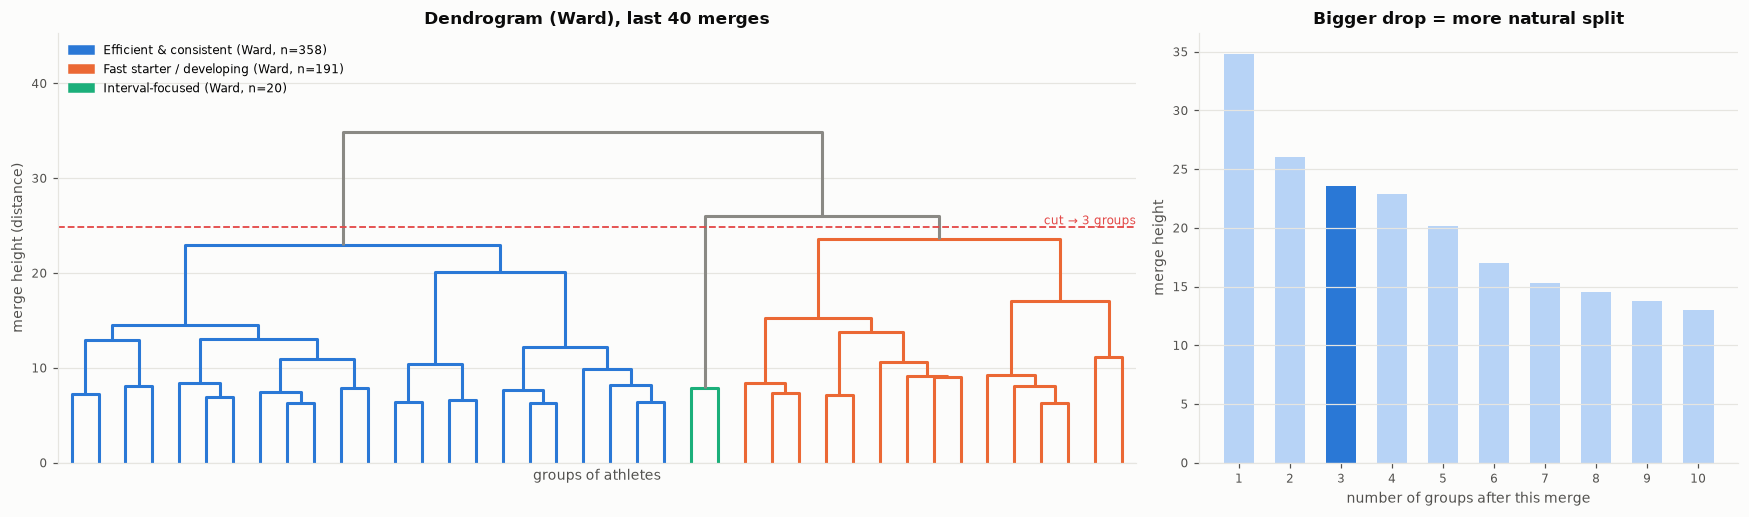

In [29]:
link = linkage(X, method="ward")
heights = link[:, 2]
cut = (heights[-K] + heights[-K + 1]) / 2          # height at which exactly K groups remain

# Cut into K groups and name them after the k-means profile they overlap with most.
hc = fcluster(link, K, criterion="maxclust") - 1
ov = pd.crosstab(km.labels_, hc).reindex(index=range(K), columns=range(K), fill_value=0)
r_, c_ = linear_sum_assignment(-ov.values)
HC_NAMES = {c: NAMES[r] for r, c in zip(r_, c_)}
core["hc_profile"] = pd.Categorical([HC_NAMES[l] for l in hc], categories=ORDER)

n_ = len(X)
def first_leaf(i):
    while i >= n_:
        i = int(link[i - n_, 0])
    return i
def link_color(i):
    return MUTED if link[i - n_, 2] > cut else COLOR[HC_NAMES[hc[first_leaf(i)]]]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 1]})
dendrogram(link, ax=a1, truncate_mode="lastp", p=40, link_color_func=link_color, no_labels=True)
from matplotlib.patches import Patch
a1.legend(handles=[Patch(color=COLOR[n], label=f"{n} (Ward, n={(core.hc_profile == n).sum()})") for n in ORDER],
          loc="upper left")
a1.set_ylim(0, heights[-1] * 1.3)
a1.axhline(cut, color=RED, ls="--", lw=1.2)
a1.text(a1.get_xlim()[1], cut, f"  cut → {K} groups", color=RED, va="bottom", ha="right", fontsize=8)
a1.set(title="Dendrogram (Ward), last 40 merges", ylabel="merge height (distance)", xlabel="groups of athletes")
a1.grid(axis="x", visible=False)

last = heights[::-1][:10]
a2.bar(range(1, 11), last, color=[BLUE if k_ == K else "#b7d3f6" for k_ in range(1, 11)], width=0.6)
a2.set(xticks=range(1, 11), xlabel="number of groups after this merge",
       ylabel="merge height", title="Bigger drop = more natural split")
a2.grid(axis="x", visible=False)
fig.tight_layout()

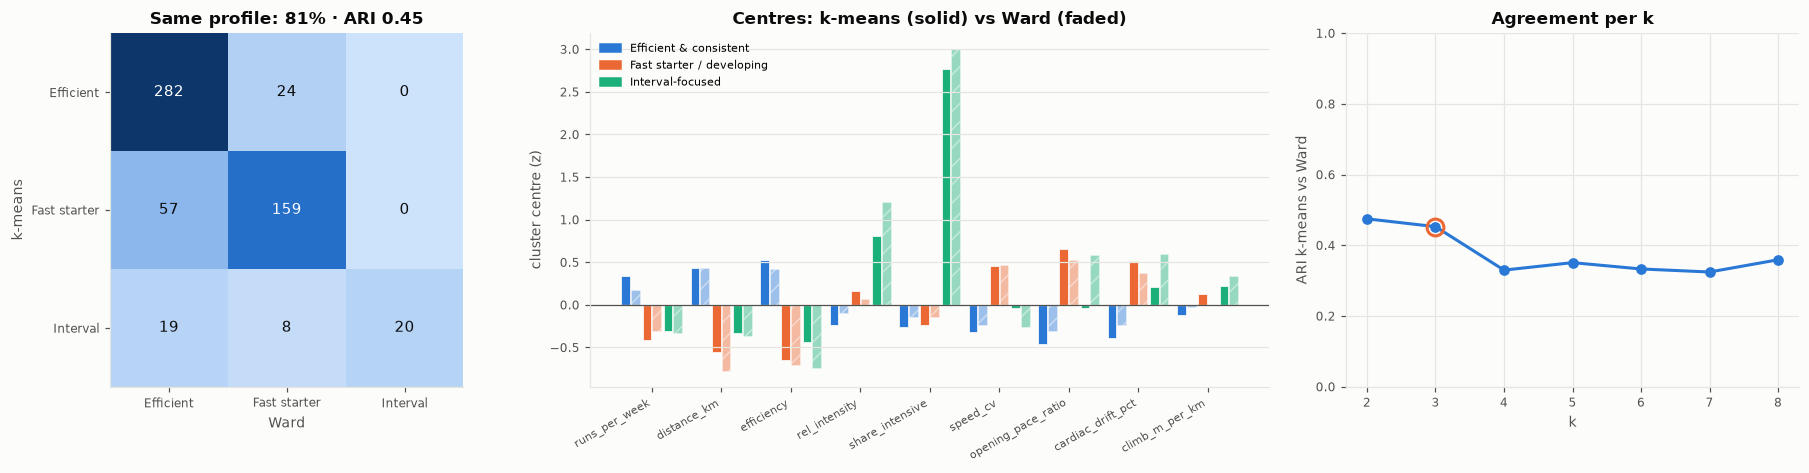

In [30]:
ct_hc = pd.crosstab(core.profile, core.hc_profile, dropna=False)
agree_hc = np.trace(ct_hc.values) / ct_hc.values.sum()
ari_hc = adjusted_rand_score(km.labels_, hc)

# ARI between Ward and k-means for other k too: are they similar at 3 by luck?
ari_k = {k_: adjusted_rand_score(KMeans(k_, n_init=20, random_state=SEED).fit_predict(X),
                                 fcluster(link, k_, criterion="maxclust")) for k_ in range(2, 9)}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1, 1.5, 1]})
ax = axes[0]
ax.imshow(ct_hc.values, cmap=SEQUENTIAL)
for r in range(K):
    for c in range(K):
        v = ct_hc.iat[r, c]
        ax.text(c, r, v, ha="center", va="center", fontsize=10, color="white" if v > ct_hc.values.max() / 2 else INK)
short = ["Efficient", "Fast starter", "Interval"]
ax.set_xticks(range(K), short, fontsize=8)
ax.set_yticks(range(K), short, fontsize=8)
ax.set(xlabel="Ward", ylabel="k-means", title=f"Same profile: {agree_hc:.0%} · ARI {ari_hc:.2f}")
ax.grid(False)

zh = pd.DataFrame(X, columns=FEATURES).groupby(core.hc_profile.to_numpy(), observed=False).mean().loc[ORDER]
ax = axes[1]
w_ = 0.38
xs = np.arange(len(FEATURES))
for k_, (src, z_, hatch) in enumerate([("k-means", zp, None), ("Ward", zh, "//")]):
    for i_, n in enumerate(ORDER):
        ax.bar(xs * 3.6 + i_ * 1.1 + k_ * 0.5, z_.loc[n].clip(-3, 3), width=0.45, color=COLOR[n],
               alpha=1 if k_ == 0 else 0.45, hatch=hatch, edgecolor="#fcfcfb", lw=0.5)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(xs * 3.6 + 1.35, FEATURES, rotation=30, ha="right", fontsize=7)
ax.set(ylabel="cluster centre (z)", title="Centres: k-means (solid) vs Ward (faded)")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=COLOR[n], label=n) for n in ORDER], fontsize=7, loc="upper left")

ax = axes[2]
ax.plot(list(ari_k), list(ari_k.values()), color=BLUE, marker="o", ms=6)
ax.plot(K, ari_k[K], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
ax.set(xlabel="k", ylabel="ARI k-means vs Ward", ylim=(0, 1), title="Agreement per k")
fig.tight_layout()

**What we see:**

* **Same fingerprints.** The centres of Ward and k-means are almost identical (middle panel): the same features stand out per profile. The profiles are therefore *not* an artefact of k-means.
* **81% same profile (ARI ≈ 0.45).** The differences sit almost entirely on the boundary between *efficient* and *fast starter*, the sliding scale we already saw. Ward finds the *interval* group smaller: about half of the k-means interval runners fall into another group with Ward.
* **No natural cut at exactly 3.** In the right panel, merge heights drop gradually after the first split, so there isn't one obvious "right" k. k = 3 is a sensible and stable choice (steps 6 and 11), not a law of nature. That fits presenting profiles as tendencies.

## Step 13 · Final labels: profile + confidence

For labelling in practice we combine everything:

* **Label** = k-means profile (simple, validated in step 11, robust in step 12).
* **Confidence** from the GMM (step 9):

| confidence | rule |
|---|---|
| **high** | GMM ≥ 80% certain **and** GMM and k-means agree |
| **medium** | typical, but between two profiles or GMM disagrees |
| **low** | atypical (typicality < 5th percentile) |

Athletes with fewer than 10 runs get **no label** (see step 3).

confidence,high,medium,low,total
label,,,,
Efficient & consistent,230,65,11,306
Fast starter / developing,74,133,9,216
Interval-focused,38,0,9,47


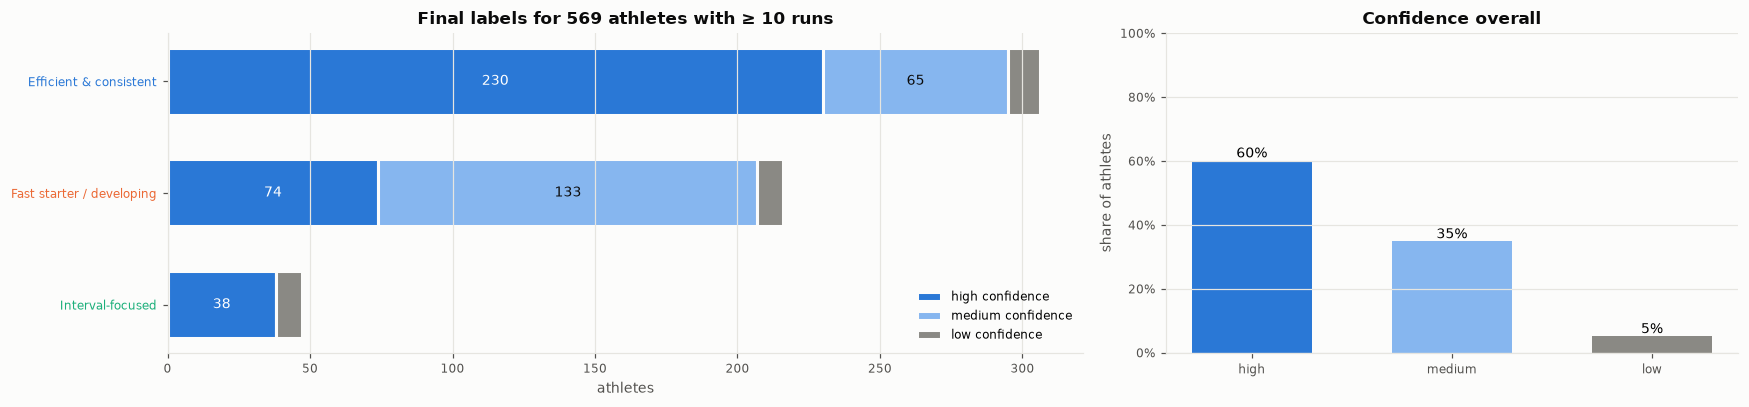

In [31]:
CONF = ["high", "medium", "low"]
CONF_COLOR = {"high": BLUE, "medium": "#86b6ef", "low": MUTED}
final = everyone[everyone.group == "core"].copy()
final["label"] = final["profile"]
final["confidence"] = pd.Categorical(np.select(
    [final.status == "atypical",
     (final.status == "confident") & (final.gmm_profile.astype(str) == final.profile.astype(str))],
    ["low", "high"], "medium"), categories=CONF)

tab = pd.crosstab(final.label, final.confidence, dropna=False).reindex(index=ORDER, columns=CONF, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
left = np.zeros(K)
for c in CONF:
    v = tab[c].values
    a1.barh(range(K), v, left=left, color=CONF_COLOR[c], edgecolor="#fcfcfb", lw=2, height=0.6, label=f"{c} confidence")
    for yi, (l_, v_) in enumerate(zip(left, v)):
        if v_ >= 12:
            a1.text(l_ + v_ / 2, yi, int(v_), ha="center", va="center", fontsize=9, color="white" if c == "high" else INK)
    left += v
a1.set_yticks(range(K), ORDER)
for tick, n in zip(a1.get_yticklabels(), ORDER):
    tick.set_color(COLOR[n])
a1.invert_yaxis()
a1.set(xlabel="athletes", title=f"Final labels for {len(final)} athletes with ≥ {MIN_WORKOUTS} runs")
a1.legend(loc="lower right")
a1.grid(axis="y", visible=False)

share = final.confidence.value_counts(normalize=True).reindex(CONF)
a2.bar(CONF, share, color=[CONF_COLOR[c] for c in CONF], width=0.6)
for xi, v in enumerate(share):
    a2.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=9)
a2.set(ylim=(0, 1), title="Confidence overall", ylabel="share of athletes")
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.grid(axis="x", visible=False)
fig.tight_layout()

final_out = pd.concat([
    final[["workouts", "label", "confidence", *ORDER]],
    low[["workouts"]].assign(label="not labelled (< 10 runs)", confidence=""),
])
final_out.round(3).to_csv(OUT / "final_labels.csv")
tab.assign(total=tab.sum(axis=1))

## Save results

In [32]:
out_cols = ["group", "workouts", *FEATURES, "profile", "km_margin", "gmm_profile", *ORDER,
            "certainty", "typicality", "status"]
everyone[out_cols].rename(columns={"profile": "kmeans_profile"}).round(4).to_csv(OUT / "athlete_profiles_all.csv")
summary = everyone.groupby("gmm_profile", observed=False).agg(
    athletes=("workouts", "size"), core=("group", lambda s: (s == "core").sum()),
    confident=("status", lambda s: (s == "confident").sum()),
    mean_certainty=("certainty", "mean"), **{f: (f, "median") for f in FEATURES})
summary.round(3).to_csv(OUT / "profile_summary.csv")
print(f"Saved to {OUT.relative_to(ROOT)}")
pd.crosstab(everyone.status, everyone.group, margins=True)

Saved to analysis\athlete_profiles\output


group,core,low-data,All
status,,,
confident,386,80,466
between profiles,154,26,180
atypical,29,86,115
All,569,192,761


## Takeaways and caveats

* **Three profiles** come back consistently with k-means: *efficient & consistent* runners (frequent, longer runs, low drift), *fast starters / developing* runners (short, uneven pace, high drift) and a small *interval-focused* group.
* **No hard boundaries.** The low silhouette, the moderate agreement between k-means and GMM, and the athletes *between profiles* all point the same way: the profiles flow into each other. Present them as tendencies (*"mostly efficient"*), not as boxes.
* **GMM pitfalls.** (1) A feature that is often exactly 0 makes a cluster collapse, which `reg_covar` prevents. (2) `predict_proba` is relative: a high probability does *not* mean the athlete fits the profile well. Always check typicality alongside it.
* **Less data → atypical.** A large share of the low-data athletes falls outside every profile. In a UI it makes sense to only show a profile after ~10 runs, or to label it "provisional".
* **Robust (step 12):** hierarchical clustering (Ward) finds the same profile fingerprints; 81% of athletes get the same profile.
* **Stable over time (step 11):** 73% of athletes keep their profile over ~11 months (chance ≈ 35%), and switches go with real changes in efficiency and drift.
* Follow-ups: cluster on *workouts* first (each athlete as a mix of workout types), or profiles over a sliding time window to follow athletes' development.